# 03 — Feature Engineering

**Mục tiêu:** biến dữ liệu đã làm sạch (`data/processed/`) thành các bảng feature theo cấu trúc *mốc dự báo* (forecast origin), sẵn sàng cho huấn luyện và đánh giá ở notebook 04. Notebook này **không huấn luyện mô hình**; nó xây feature, kiểm tra tính đúng đắn và chống rò rỉ, và tính các baseline để có mốc so sánh.

**Đầu vào:** `data/processed/*_cleaned.parquet` (từ 02), `data/interim/eda_cache/*` (từ 01), `reports/00_environment_snapshot.json` (từ 00).
**Đầu ra:** `data/processed/features/*.parquet` (mỗi mốc một file), `reports/table/03_*.csv`, `reports/03_feature_engineering_report.json`, `reports/03_config.json`, `reports/03_encodings.json`.

---

## 0. Những gì được kế thừa từ notebook 00, 01, 02

Các quyết định thiết kế bên dưới đều dựa trên bằng chứng đã có trong ba notebook trước.

| Phát hiện | Nơi có bằng chứng | Quyết định trong 03 |
|---|---|---|
| Horizon 16 ngày; metric NWRMSLE (trọng số perishable 1,25); target nên là `log1p(clip(y, 0))` | 00 mục 1.1–1.2; 01 mục 7.14 | Nhãn `y_log`, trọng số `w`, hàm `nwrmsle()` |
| Train **thưa** (34% lưới), test là lưới đầy đủ; ngày vắng trong cửa sổ hoạt động coi là 0 | 01 mục 7.9 | Dựng **tensor lịch sử dày** theo từng mốc; ngày vắng = 0 (loại các ngày trước khi cặp ra mắt khỏi mẫu số) |
| Cửa hàng không có dữ liệu cả ngày (25/12, chưa mở) không phải doanh số 0 | 01 mục 7.12; 02 (4 ngày 25/12) | Bỏ dòng mục tiêu của store-day không có dữ liệu |
| Số dòng/ngày thay đổi mạnh theo thời gian (độ phủ) | 01 mục 7.9 | Nhiều mốc dự báo; giữ ngày mốc để 04 thử các cửa sổ huấn luyện (toàn bộ, từ 2015-06, từ 2016) |
| `onpromotion` thiếu trước 2014-04-01 (có cấu trúc) | 02 mục 4.1 | Cờ `promo_known`; không điền `False` cho dòng thiếu |
| Tỷ lệ khuyến mãi của test (5,9%) thấp hơn cuối train (10,7%), một phần do mẫu số; khuyến mãi ở train chỉ quan sát được khi có dòng bán | 01 mục 7.10 | Tỷ lệ khuyến mãi tính trên **cùng mẫu số dày** (toàn bộ cặp trong universe); nhóm *khuyến mãi tương lai* được gắn cờ rủi ro và đo ở mục 11.3 |
| Chu kỳ tuần mạnh, hệ số thứ ổn định; hiệu ứng đầu/cuối tháng thật | 01 mục 7.13, 7.15 | Feature lịch + trung bình theo **cùng thứ trong tuần** |
| Động đất 16/04/2016 làm méo doanh số | 01 mục 7.13, 7.14 | Loại các mốc có cửa sổ mục tiêu hoặc 28 ngày lịch sử chạm vào giai đoạn này |
| ≈ 29% dòng test không có lịch sử gần đây của chính cặp | 01 mục 7.16 | Cột `pair_status` (4 nhóm) và feature phân cấp theo item/cửa hàng |
| `holidays_events` có 14 dòng trùng khóa; có `transferred` | 02 mục 5.1 | Gom theo `(date, locale, locale_name)` trước khi nối; xử lý `Transfer` |
| `transactions` và `dcoilwtico` không biết trước cho horizon; giá dầu tương quan giả | 00 mục 1.5; 01 mục 7.17 | Chỉ dùng dạng đã biết tại mốc dự báo; giá dầu để ở nhóm *exploratory* |
| RAM khả dụng ≈ 1,9–2,1 GB, 8 nhân CPU, không GPU; chunk đề xuất 250.000 | 00 mục 4.2–4.3 | Xử lý theo từng mốc, ghi Parquet từng khối, giới hạn số dòng huấn luyện |

---

## 1. Thiết kế

### 1.1 Cấu trúc mốc dự báo (forecast origin)

Với mỗi **mốc** `T` (ngày cuối cùng được quan sát), mỗi cặp `(store, item)` và mỗi bước `h = 1..16`, một dòng dữ liệu mô tả việc dự báo `unit_sales` của ngày `T + h`. Mọi feature của dòng đó chỉ dùng thông tin **biết tại ngày `T`**, cộng với các thông tin vốn biết trước cho tương lai (lịch, ngày lễ, khuyến mãi được cung cấp, metadata).

- Một mô hình duy nhất cho mọi `h` (feature `h` và `dow` cho phép phân biệt bước dự báo).
- Các mốc cách nhau `ORIGIN_STEP_DAYS` ngày, **nguyên tố cùng nhau với 7** để thứ trong tuần của mốc bao phủ đủ cả 7 giá trị. Nếu mọi mốc cùng thứ thì `dow` và `h` bị phụ thuộc hoàn toàn vào nhau và mô hình không phân tách được hai hiệu ứng này; khi áp dụng lên mốc test (thứ khác) sẽ lệch.
- Mốc kiểm định chính là 16 ngày cuối của train; mốc kiểm định thứ hai bám cùng thời điểm mùa vụ năm trước.

### 1.2 Lịch sử dày theo từng mốc

Từ train thưa, mỗi mốc dựng một ma trận `A` kích thước `(số cặp) × LOOKBACK` chứa `log1p(clip(y, 0))`, ngày không có dòng bằng 0. Khi tính trung bình theo cửa sổ `W`, mẫu số là số ngày **kể từ ngày cặp ra mắt** (tối đa `W`), để các ngày trước khi cặp tồn tại không bị tính là doanh số 0.

### 1.3 Chống rò rỉ

1. Feature lịch sử chỉ đọc cột ngày `≤ T` của `A`.
2. Chỉ dùng `first_date` của cặp từ cache (an toàn vì `first_date ≤ T` là điều kiện chọn cặp); **không** dùng `last_date` toàn cục.
3. Hai kiểm thử tự động ở mục 10: (a) so sánh với cài đặt brute-force độc lập bằng pandas; (b) làm nhiễu phần tương lai và kiểm tra feature không đổi.
4. **Rò rỉ qua sự tồn tại của dòng (cần chú ý riêng):** ở train, trạng thái khuyến mãi của một ngày chỉ được ghi khi cặp có dòng bán, nên `promo_t = 1` kéo theo `y > 0`. Test không có ràng buộc này. Các feature khuyến mãi theo ngày mục tiêu được tách thành nhóm riêng, được đo ở mục 11.3 và cần được kiểm tra bằng thí nghiệm bỏ-đi (ablation) ở notebook 04.

## 2. Thiết lập

In [1]:
import gc
import json
import math
import time
import warnings
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.dataset as ds
import pyarrow.parquet as pq
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
np.random.seed(SEED)


def find_project_root(start: Path) -> Path:
    for candidate in [start.resolve(), *start.resolve().parents]:
        if (candidate / "data" / "raw" / "train.csv").exists():
            return candidate
    raise FileNotFoundError("Không tìm thấy data/raw/train.csv. Hãy mở notebook trong repository của project.")


PROJECT_ROOT = find_project_root(Path.cwd())
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FEATURE_DIR = PROCESSED_DIR / "features"
CACHE_DIR = PROJECT_ROOT / "data" / "interim" / "eda_cache"
REPORT_DIR = PROJECT_ROOT / "reports"
REPORT_TABLE_DIR = REPORT_DIR / "table"
for directory in (FEATURE_DIR, REPORT_TABLE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print("Project root :", PROJECT_ROOT)
print("Feature dir  :", FEATURE_DIR)
try:
    import psutil
    print(f"Available RAM: {psutil.virtual_memory().available / 1024**3:.2f} GB")
except ImportError:
    psutil = None

Project root : /home/phat/Documents/Project/Machine Learning/Grocery-sales-forecast
Feature dir  : /home/phat/Documents/Project/Machine Learning/Grocery-sales-forecast/data/processed/features
Available RAM: 1.67 GB


### 2.1 Cấu hình

Các tham số có thể chỉnh. Giá trị mặc định được chọn cho máy của bạn (RAM khả dụng ≈ 2 GB): tổng số dòng huấn luyện giới hạn ở mức `TARGET_TRAIN_ROWS`, và sẽ được chia đều cho các mốc bằng cách lấy mẫu cặp.

In [2]:
# ----------------------------------------------------------------- đọc snapshot của notebook 00 (nếu có)
snapshot_path = REPORT_DIR / "00_environment_snapshot.json"
if snapshot_path.exists():
    snapshot = json.loads(snapshot_path.read_text(encoding="utf-8"))
    HORIZON = int(snapshot["forecast"]["horizon_days"])
    TEST_ORIGIN = pd.Timestamp(snapshot["forecast"]["expected_train_end"])
    RECOMMENDED_CHUNK_SIZE = int(snapshot["chunk"]["recommended_chunk_size"])
    PERISHABLE_WEIGHT = float(snapshot["metric"]["perishable_weight"])
    print("Đã đọc snapshot của notebook 00.")
else:
    snapshot = None
    HORIZON, TEST_ORIGIN, RECOMMENDED_CHUNK_SIZE, PERISHABLE_WEIGHT = 16, pd.Timestamp("2017-08-15"), 250_000, 1.25
    print("Không thấy snapshot của notebook 00; dùng giá trị mặc định.")

# ----------------------------------------------------------------- cấu hình cửa sổ lịch sử
LOOKBACK = 224                       # số ngày lịch sử dày cho mỗi mốc (32 tuần)
WINDOWS = [3, 7, 14, 28, 56, 112, 224]
ACT_WINDOWS = [7, 14, 28, 56, 112]
MEANPOS_WINDOWS = [28, 112]
DOW_OCCURRENCES = [4, 8, 16]         # số lần xuất hiện của cùng thứ trong tuần

# ----------------------------------------------------------------- cấu hình các mốc
LAST_TRAIN_ORIGIN = TEST_ORIGIN - pd.Timedelta(days=HORIZON)     # mốc cuối cùng có nhãn đầy đủ trong train
ORIGIN_STEP_DAYS = 13                # nguyên tố cùng nhau với 7
TRAIN_ORIGIN_START = pd.Timestamp("2015-06-01")
SEASONAL_VALID_ORIGIN = pd.Timestamp("2016-08-15")               # cùng thời điểm mùa vụ năm trước

QUAKE_START, QUAKE_END = pd.Timestamp("2016-04-16"), pd.Timestamp("2016-05-15")
QUAKE_LOOKBACK_EXCLUDE_DAYS = 28

# ----------------------------------------------------------------- ngân sách dữ liệu
TARGET_TRAIN_ROWS = 3_000_000        # tổng số dòng của các mốc huấn luyện (giảm nếu thiếu RAM ở notebook 04)
VALID_PAIR_FRAC = {"valid_last16": 1.0, "valid_seasonal": 0.5}
FORCE_REBUILD = False                # True: dựng lại các file đã tồn tại

# ----------------------------------------------------------------- hằng số khác
PROMO_TRACKING_START = pd.Timestamp("2014-04-01")   # mốc xác minh ở 02 mục 4.1
KEY_MUL = 10_000_000                 # khóa cặp = store * KEY_MUL + item (item_nbr < 1e7)
STATUS_NAMES = {0: "cặp cũ, có bán trong 28 ngày", 1: "cặp cũ, ngừng bán > 28 ngày",
                2: "cặp mới, item đã có", 3: "cặp mới, item chưa từng có"}

assert math.gcd(ORIGIN_STEP_DAYS, 7) == 1, "ORIGIN_STEP_DAYS phải nguyên tố cùng nhau với 7"
assert LOOKBACK >= max(WINDOWS)
print(f"HORIZON={HORIZON} | TEST_ORIGIN={TEST_ORIGIN.date()} | LAST_TRAIN_ORIGIN={LAST_TRAIN_ORIGIN.date()} | LOOKBACK={LOOKBACK}")

Đã đọc snapshot của notebook 00.
HORIZON=16 | TEST_ORIGIN=2017-08-15 | LAST_TRAIN_ORIGIN=2017-07-30 | LOOKBACK=224


### 2.2 Metric và hàm kiểm thử

`nwrmsle()` giống định nghĩa ở notebook 00 (mục 1.2); được đặt lại ở đây để notebook này chạy độc lập.

In [3]:
def nwrmsle(y_true, y_pred, perishable, perishable_weight=PERISHABLE_WEIGHT):
    y_true = np.clip(np.asarray(y_true, dtype="float64"), 0, None)
    y_pred = np.clip(np.asarray(y_pred, dtype="float64"), 0, None)
    w = np.where(np.asarray(perishable) == 1, perishable_weight, 1.0)
    return float(np.sqrt(np.sum(w * (np.log1p(y_pred) - np.log1p(y_true)) ** 2) / np.sum(w)))


assert nwrmsle([0, 3], [0, 3], [0, 1]) == 0.0
assert abs(nwrmsle([1], [3], [0]) - np.log(2)) < 1e-12
print("nwrmsle(): PASS")

nwrmsle(): PASS


## 3. Nạp dữ liệu đã làm sạch và cache

In [4]:
required = ["train_cleaned.parquet", "test_cleaned.parquet", "stores_cleaned.parquet", "items_cleaned.parquet",
            "oil_cleaned.parquet", "holidays_events_cleaned.parquet", "transactions_cleaned.parquet"]
missing = [n for n in required if not (PROCESSED_DIR / n).exists()]
if missing:
    raise FileNotFoundError(f"Thiếu file đã làm sạch: {missing}. Hãy chạy notebook 02 trước.")

stores = pd.read_parquet(PROCESSED_DIR / "stores_cleaned.parquet")
items = pd.read_parquet(PROCESSED_DIR / "items_cleaned.parquet")
oil = pd.read_parquet(PROCESSED_DIR / "oil_cleaned.parquet")
holidays = pd.read_parquet(PROCESSED_DIR / "holidays_events_cleaned.parquet")
transactions = pd.read_parquet(PROCESSED_DIR / "transactions_cleaned.parquet")

for frame, col in ((oil, "date"), (holidays, "date"), (transactions, "date")):
    frame[col] = pd.to_datetime(frame[col])

# ----------------------------------------------------------------- cache của notebook 01
cache_ext = "parquet" if all((CACHE_DIR / f"{n}.parquet").exists() for n in ("pair", "store_day")) else "csv"
for name in ("pair", "store_day"):
    if not (CACHE_DIR / f"{name}.{cache_ext}").exists():
        raise FileNotFoundError(f"Thiếu cache {name} ở {CACHE_DIR}. Hãy chạy mục 1.1 của notebook 01.")


def read_cache(name):
    path = CACHE_DIR / f"{name}.{cache_ext}"
    return pd.read_parquet(path) if cache_ext == "parquet" else pd.read_csv(path)


pair_tbl = read_cache("pair")[["store_nbr", "item_nbr", "first_date"]].copy()
pair_tbl["first_date"] = pd.to_datetime(pair_tbl["first_date"])
pair_tbl["key"] = pair_tbl["store_nbr"].astype("int64") * KEY_MUL + pair_tbl["item_nbr"].astype("int64")
pair_tbl = pair_tbl.sort_values("key").reset_index(drop=True)

store_day = read_cache("store_day")
store_day["date"] = pd.to_datetime(store_day["date"])

print(f"stores={len(stores)} | items={len(items)} | pairs (cache)={len(pair_tbl):,} | store-day (cache)={len(store_day):,}")
print(f"oil={len(oil)} | holidays={len(holidays)} | transactions={len(transactions):,}")

stores=54 | items=4100 | pairs (cache)=174,685 | store-day (cache)=83,606
oil=1218 | holidays=350 | transactions=83,488


### 3.1 Chỉ mục row group của `train_cleaned.parquet`

File train được sắp theo `(date, store_nbr, item_nbr)` và ghi theo chunk, nên mỗi row group chỉ chứa một dải ngày hẹp. Chỉ số dải ngày của row group cho phép đọc **đúng cửa sổ ngày cần cho một mốc** mà không quét cả file.

In [5]:
TRAIN_PQ = PROCESSED_DIR / "train_cleaned.parquet"
pf = pq.ParquetFile(TRAIN_PQ)
date_col_idx = pf.schema_arrow.names.index("date")

records = []
for i in range(pf.num_row_groups):
    rg = pf.metadata.row_group(i)
    st = rg.column(date_col_idx).statistics
    if st is not None and st.has_min_max:
        lo, hi = pd.Timestamp(st.min), pd.Timestamp(st.max)
    else:                                              # dự phòng: đọc cột date
        col = pd.to_datetime(pf.read_row_group(i, columns=["date"]).column("date").to_pandas())
        lo, hi = col.min(), col.max()
    records.append((i, lo, hi, rg.num_rows))

rg_df = pd.DataFrame(records, columns=["rg", "min_date", "max_date", "rows"])
is_sorted = bool((rg_df["min_date"].iloc[1:].to_numpy() >= rg_df["max_date"].iloc[:-1].to_numpy()).all())
TRAIN_FIRST_DATE, TRAIN_LAST_DATE = rg_df["min_date"].min(), rg_df["max_date"].max()

print(f"Row groups: {len(rg_df):,} | tổng dòng: {int(rg_df['rows'].sum()):,} | file sắp theo ngày: {is_sorted}")
print(f"Phạm vi ngày train: {TRAIN_FIRST_DATE.date()} → {TRAIN_LAST_DATE.date()}")
assert is_sorted, "File train không sắp theo ngày; chỉ mục row group không áp dụng được."
assert TRAIN_LAST_DATE == TEST_ORIGIN, f"Ngày cuối train ({TRAIN_LAST_DATE.date()}) khác mốc test ({TEST_ORIGIN.date()})"

Row groups: 1,255 | tổng dòng: 125,497,040 | file sắp theo ngày: True
Phạm vi ngày train: 2013-01-01 → 2017-08-15


## 4. Bảng tra cứu tĩnh

Các bảng nhỏ biết trước cho tương lai: mã hóa metadata, lịch ngày lễ theo cửa hàng, tồn tại dữ liệu theo store-day.

### 4.1 Mã hóa metadata

In [6]:
store_ids = np.sort(stores["store_nbr"].unique()).astype(np.int64)
store_pos = np.full(int(store_ids.max()) + 2, -1, dtype=np.int64)
store_pos[store_ids] = np.arange(len(store_ids))
N_STORES = len(store_ids)

stores_sorted = stores.set_index("store_nbr").loc[store_ids].reset_index()


def codes_of(series):
    categories = sorted(pd.Series(series).dropna().astype(str).unique())
    return categories, {c: i for i, c in enumerate(categories)}


type_cats, type_map = codes_of(stores_sorted["type"])
state_cats, state_map = codes_of(stores_sorted["state"])
city_cats, city_map = codes_of(stores_sorted["city"])
family_cats, family_map = codes_of(items["family"])

store_static = pd.DataFrame({
    "store_nbr": stores_sorted["store_nbr"].astype("int64"),
    "store_type": stores_sorted["type"].astype(str).map(type_map).astype("int8"),
    "store_cluster": stores_sorted["cluster"].astype("int16"),
    "store_state": stores_sorted["state"].astype(str).map(state_map).astype("int16"),
    "store_city": stores_sorted["city"].astype(str).map(city_map).astype("int16"),
})
item_static = items[["item_nbr", "family", "class", "perishable"]].copy()
item_static["item_family"] = item_static["family"].astype(str).map(family_map).astype("int16")
item_static["item_class"] = item_static["class"].astype("int32")
item_static["perishable"] = item_static["perishable"].astype("int8")
item_static = item_static.drop(columns=["family", "class"]).sort_values("item_nbr").reset_index(drop=True)

encodings = {"store_type": type_cats, "store_state": state_cats, "store_city": city_cats, "item_family": family_cats}
(REPORT_DIR / "03_encodings.json").write_text(json.dumps(encodings, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"{N_STORES} cửa hàng | {len(item_static):,} mặt hàng | {len(family_cats)} family | đã lưu reports/03_encodings.json")

54 cửa hàng | 4,100 mặt hàng | 33 family | đã lưu reports/03_encodings.json


### 4.2 Lịch ngày lễ theo cửa hàng

Quy tắc (từ 02, mục 5.1 và 01, mục 7.13):

- **Ngày lễ hiệu lực:** `type ∈ {Holiday, Additional, Bridge}` và `transferred = False`, hoặc `type = Transfer` (ngày nghỉ thực của lễ bị dời). Dòng `transferred = True` **không** phải ngày nghỉ.
- `Event` (ví dụ Black Friday, động đất) là cờ riêng, `Work Day` là ngày làm việc bù.
- Gom theo `(date, locale, locale_name)` bằng `max` **trước khi** gán, để các dòng trùng khóa không nhân lên.
- `National` áp dụng mọi cửa hàng, `Regional` khớp `state`, `Local` khớp `city`.

In [7]:
CAL0 = pd.Timestamp("2013-01-01")
hol = holidays.copy()
hol["transferred"] = hol["transferred"].astype(str).str.strip().str.lower().eq("true")
hol["is_hol"] = (hol["type"].isin(["Holiday", "Additional", "Bridge"]) & ~hol["transferred"]) | (hol["type"] == "Transfer")
hol["is_event"] = hol["type"] == "Event"
hol["is_workday"] = hol["type"] == "Work Day"

grouped = hol.groupby(["date", "locale", "locale_name"], as_index=False)[["is_hol", "is_event", "is_workday"]].max()
print(f"Gom {len(hol)} dòng holidays → {len(grouped)} nhóm (date, locale, locale_name)")

CAL1 = max(TEST_ORIGIN + pd.Timedelta(days=HORIZON), hol["date"].max())
N_CAL = (CAL1 - CAL0).days + 1

nat_hol = np.zeros(N_CAL, dtype=np.int8)
ev_nat = np.zeros(N_CAL, dtype=np.int8)
workday_nat = np.zeros(N_CAL, dtype=np.int8)
reg_hol = np.zeros((N_STORES, N_CAL), dtype=np.int8)
loc_hol = np.zeros((N_STORES, N_CAL), dtype=np.int8)

state_arr = stores_sorted["state"].astype(str).to_numpy()
city_arr = stores_sorted["city"].astype(str).to_numpy()

for r in grouped.itertuples(index=False):
    d = (r.date - CAL0).days
    if d < 0 or d >= N_CAL:
        continue
    if r.locale == "National":
        nat_hol[d] |= int(r.is_hol); ev_nat[d] |= int(r.is_event); workday_nat[d] |= int(r.is_workday)
    elif r.locale == "Regional":
        reg_hol[state_arr == str(r.locale_name), d] |= int(r.is_hol)
    elif r.locale == "Local":
        loc_hol[city_arr == str(r.locale_name), d] |= int(r.is_hol)

hol_days = np.flatnonzero(nat_hol)
all_days = np.arange(N_CAL)
nxt = np.searchsorted(hol_days, all_days, side="left")
prv = np.searchsorted(hol_days, all_days, side="right") - 1
CAP = 30
days_to_nat_hol = np.where(nxt < len(hol_days), hol_days[np.minimum(nxt, len(hol_days) - 1)] - all_days, CAP).clip(0, CAP).astype(np.int16)
days_since_nat_hol = np.where(prv >= 0, all_days - hol_days[np.maximum(prv, 0)], CAP).clip(0, CAP).astype(np.int16)

print(f"Lịch: {CAL0.date()} → {CAL1.date()} ({N_CAL} ngày) | lễ quốc gia hiệu lực: {int(nat_hol.sum())} ngày | Event: {int(ev_nat.sum())} | Work Day: {int(workday_nat.sum())}")

Gom 350 dòng holidays → 343 nhóm (date, locale, locale_name)
Lịch: 2013-01-01 → 2017-12-26 (1821 ngày) | lễ quốc gia hiệu lực: 91 ngày | Event: 55 | Work Day: 5


### 4.3 Bảng lịch theo ngày và tồn tại dữ liệu theo store-day

`store_day_exists[s, d] = True` khi cửa hàng `s` có **ít nhất một dòng** trong ngày `d`. Dòng mục tiêu của store-day không tồn tại (25/12, cửa hàng chưa mở) bị loại, vì đó là đóng cửa chứ không phải doanh số 0.

In [8]:
def calendar_table(dates):
    d = pd.DatetimeIndex(dates)
    dim = d.days_in_month.to_numpy()
    day = d.day.to_numpy()
    year = d.year.to_numpy()
    xmas_this = pd.to_datetime(pd.DataFrame({"year": year, "month": 12, "day": 25}))
    xmas_year = np.where(d.to_numpy() > xmas_this.to_numpy(), year + 1, year)
    xmas_next = pd.to_datetime(pd.DataFrame({"year": xmas_year, "month": 12, "day": 25}))
    return pd.DataFrame({
        "dow": d.dayofweek.to_numpy().astype(np.int8),
        "dom": day.astype(np.int8),
        "month": d.month.to_numpy().astype(np.int8),
        "woy": d.isocalendar().week.to_numpy().astype(np.int8),
        "days_to_month_end": (dim - day).astype(np.int8),
        "is_payday15": ((day == 15) | (day == dim)).astype(np.int8),
        "is_jan1": ((d.month == 1) & (day == 1)).astype(np.int8),
        "is_dec24_31": ((d.month == 12) & (day >= 24)).astype(np.int8),
        "days_to_xmas": np.minimum((xmas_next.to_numpy() - d.to_numpy()) / np.timedelta64(1, "D"), 60).astype(np.int8),
    }, index=d)


store_day_exists = np.zeros((N_STORES, N_CAL), dtype=bool)
sd_pos = store_pos[store_day["store_nbr"].to_numpy().astype(np.int64)]
sd_day = (store_day["date"] - CAL0).dt.days.to_numpy()
ok = (sd_pos >= 0) & (sd_day >= 0) & (sd_day < N_CAL)
store_day_exists[sd_pos[ok], sd_day[ok]] = True

store_first_date = store_day.groupby("store_nbr")["date"].min()
print(f"store-day tồn tại: {int(store_day_exists.sum()):,} | mẫu lịch:")
display(calendar_table(pd.date_range("2017-08-16", periods=3)))

store-day tồn tại: 83,606 | mẫu lịch:


,dow,dom,month,woy,days_to_month_end,is_payday15,is_jan1,is_dec24_31,days_to_xmas
2017-08-16,2,16,8,33,15,0,0,0,60
2017-08-17,3,17,8,33,14,0,0,0,60
2017-08-18,4,18,8,33,13,0,0,0,60


## 5. Kế hoạch các mốc dự báo

Các mốc huấn luyện đi lùi từ `LAST_TRAIN_ORIGIN` với bước `ORIGIN_STEP_DAYS`. Mốc đầu tiên (`k = 0`) đồng thời là mốc kiểm định chính (16 ngày cuối của train).

**Quy tắc chống chồng lấn khi huấn luyện ở notebook 04:** một mốc huấn luyện `T_tr` chỉ được dùng cho fold có mốc `T_f` nếu `T_tr + HORIZON ≤ T_f`, tức nhãn của mốc huấn luyện không chạm vào cửa sổ mục tiêu của fold. Notebook này lưu sẵn cột `origin` để 04 áp dụng quy tắc.

In [9]:
def overlaps(a0, a1, b0, b1):
    return not (a1 < b0 or a0 > b1)


# ----------------------------------------------------------------- liệt kê mốc ứng viên
candidates = []
t = LAST_TRAIN_ORIGIN
k = 0
while t >= TRAIN_ORIGIN_START:
    candidates.append((k, t))
    t = t - pd.Timedelta(days=ORIGIN_STEP_DAYS)
    k += 1

n_known_by_origin = lambda T: int((pair_tbl["first_date"] <= T).sum())

plan = []
for k, T in candidates:
    tgt0, tgt1 = T + pd.Timedelta(days=1), T + pd.Timedelta(days=HORIZON)
    quake_hit = overlaps(tgt0, tgt1, QUAKE_START, QUAKE_END) or overlaps(
        T - pd.Timedelta(days=QUAKE_LOOKBACK_EXCLUDE_DAYS - 1), T, QUAKE_START, QUAKE_END)
    role = "valid_last16" if k == 0 else "train"
    plan.append({"k": k, "origin": T, "role": role, "weekday": T.day_name(), "n_known_pairs": n_known_by_origin(T),
                 "excluded_quake": bool(quake_hit and role == "train")})

# mốc kiểm định theo mùa vụ năm trước
if pd.Timestamp(SEASONAL_VALID_ORIGIN) + pd.Timedelta(days=HORIZON) <= TEST_ORIGIN:
    plan.append({"k": -1, "origin": SEASONAL_VALID_ORIGIN, "role": "valid_seasonal", "weekday": SEASONAL_VALID_ORIGIN.day_name(),
                 "n_known_pairs": n_known_by_origin(SEASONAL_VALID_ORIGIN), "excluded_quake": False})

plan.append({"k": -2, "origin": TEST_ORIGIN, "role": "test", "weekday": TEST_ORIGIN.day_name(),
             "n_known_pairs": n_known_by_origin(TEST_ORIGIN), "excluded_quake": False})

plan_df = pd.DataFrame(plan)

# ----------------------------------------------------------------- chia ngân sách dòng huấn luyện
train_mask = (plan_df["role"] == "train") & ~plan_df["excluded_quake"]
expected_full_rows = float((plan_df.loc[train_mask, "n_known_pairs"] * HORIZON).sum())
TRAIN_PAIR_FRAC = float(min(1.0, TARGET_TRAIN_ROWS / max(expected_full_rows, 1.0)))

plan_df["pair_frac"] = np.select(
    [train_mask, plan_df["role"] == "valid_last16", plan_df["role"] == "valid_seasonal", plan_df["role"] == "test"],
    [TRAIN_PAIR_FRAC, VALID_PAIR_FRAC["valid_last16"], VALID_PAIR_FRAC["valid_seasonal"], 1.0], default=0.0)
plan_df["use"] = plan_df["pair_frac"] > 0
plan_df["est_rows"] = (plan_df["n_known_pairs"] * HORIZON * plan_df["pair_frac"]).where(plan_df["role"] != "test", other=np.nan)
plan_df["file"] = plan_df.apply(lambda r: f"{r['role']}_{r['origin'].strftime('%Y%m%d')}.parquet", axis=1)

print(f"Số mốc huấn luyện dùng: {int(train_mask.sum())} | bị loại do động đất: {int((plan_df['role'].eq('train') & plan_df['excluded_quake']).sum())}")
print(f"Tỷ lệ lấy mẫu cặp cho mốc huấn luyện: {TRAIN_PAIR_FRAC:.4f}  (mục tiêu {TARGET_TRAIN_ROWS:,} dòng)")
print("Phân bố thứ trong tuần của các mốc huấn luyện:")
display(plan_df[train_mask]["weekday"].value_counts().rename_axis("weekday").to_frame("số mốc").T)
display(plan_df[plan_df["role"] != "train"][["role", "origin", "weekday", "n_known_pairs", "pair_frac", "est_rows", "file"]])

Số mốc huấn luyện dùng: 54 | bị loại do động đất: 6
Tỷ lệ lấy mẫu cặp cho mốc huấn luyện: 0.0232  (mục tiêu 3,000,000 dòng)
Phân bố thứ trong tuần của các mốc huấn luyện:


weekday,Wednesday,Monday,Tuesday,Thursday,Friday,Saturday,Sunday
số mốc,9,8,8,8,7,7,7


,role,origin,weekday,n_known_pairs,pair_frac,est_rows,file
0,valid_last16,2017-07-30,Sunday,174140,1.0,2786240.0,valid_last16_20170730.parquet
61,valid_seasonal,2016-08-15,Monday,151876,0.5,1215008.0,valid_seasonal_20160815.parquet
62,test,2017-08-15,Tuesday,174685,1.0,NaN,test_20170815.parquet


**Đọc kết quả:** bảng thứ trong tuần phải có đủ 7 giá trị với số mốc gần đều nhau; nếu thiếu thứ nào, đổi `ORIGIN_STEP_DAYS` hoặc `TRAIN_ORIGIN_START`. Mốc `test` có thứ khác với các mốc huấn luyện (hoặc trùng) đều không sao miễn là mô hình đã thấy đủ 7 thứ.

## 6. Đọc lịch sử thành tensor dày

Hàm `build_tensors` đọc **đúng cửa sổ** `[T - LOOKBACK + 1, T + HORIZON]` từ file train theo từng row group, rồi điền:

- `A[p, j]`: `log1p(clip(unit_sales, 0))` ở ngày `j` của cửa sổ lịch sử (0 nếu không có dòng).
- `PM[p, j]`: trạng thái khuyến mãi (`-1` chưa biết/không có dòng, `0`, `1`) cho cả lịch sử và `HORIZON` ngày tương lai.
- `Y[p, h]`: `unit_sales` thô của các ngày tương lai (nhãn; chỉ dùng làm nhãn, **không** dùng tính feature).

Với mốc test, trạng thái khuyến mãi tương lai và `id` lấy từ `test_cleaned.parquet`.

In [10]:
def make_key(store, item):
    return np.asarray(store, dtype=np.int64) * KEY_MUL + np.asarray(item, dtype=np.int64)


def read_window(start, end, columns):
    selected = rg_df[(rg_df["max_date"] >= start) & (rg_df["min_date"] <= end)]
    for rg in selected["rg"]:
        yield pf.read_row_group(int(rg), columns=columns)


def promo_status(column):
    valid = pc.is_valid(column).to_numpy(zero_copy_only=False)
    values = pc.fill_null(column, False).to_numpy(zero_copy_only=False).astype(np.int8)
    return np.where(valid, values, -1).astype(np.int8)


def build_tensors(origin, keys_sorted):
    start = origin - pd.Timedelta(days=LOOKBACK - 1)
    end = origin + pd.Timedelta(days=HORIZON)
    P = len(keys_sorted)
    A = np.zeros((P, LOOKBACK), dtype=np.float32)
    PM = np.full((P, LOOKBACK + HORIZON), -1, dtype=np.int8)
    Y = np.zeros((P, HORIZON), dtype=np.float32)
    start64 = np.datetime64(start.strftime("%Y-%m-%d"), "D")

    for tbl in read_window(start, end, ["date", "store_nbr", "item_nbr", "unit_sales", "onpromotion"]):
        day = (tbl.column("date").to_numpy().astype("datetime64[D]") - start64).astype(np.int64)
        in_range = (day >= 0) & (day < LOOKBACK + HORIZON)
        if not in_range.any():
            continue
        key = make_key(tbl.column("store_nbr").to_numpy(), tbl.column("item_nbr").to_numpy())
        pos = np.searchsorted(keys_sorted, key)
        hit = keys_sorted[np.minimum(pos, P - 1)] == key
        m = in_range & hit
        if not m.any():
            continue
        y = tbl.column("unit_sales").to_numpy()
        status = promo_status(tbl.column("onpromotion"))
        hist = m & (day < LOOKBACK)
        fut = m & (day >= LOOKBACK)
        A[pos[hist], day[hist]] = np.log1p(np.clip(y[hist], 0, None))
        Y[pos[fut], day[fut] - LOOKBACK] = y[fut]
        PM[pos[m], day[m]] = status[m]
    return A, PM, Y


test_cleaned_path = PROCESSED_DIR / "test_cleaned.parquet"


def load_test_future(keys_sorted, origin):
    # Khuyến mãi và id của test trên lưới cặp x ngày; chỉ dùng cho mốc test.
    tbl = pq.read_table(test_cleaned_path, columns=["id", "date", "store_nbr", "item_nbr", "onpromotion"])
    day = (tbl.column("date").to_numpy().astype("datetime64[D]") - np.datetime64(origin.strftime("%Y-%m-%d"), "D")).astype(np.int64) - 1
    key = make_key(tbl.column("store_nbr").to_numpy(), tbl.column("item_nbr").to_numpy())
    pos = np.searchsorted(keys_sorted, key)
    assert (keys_sorted[np.minimum(pos, len(keys_sorted) - 1)] == key).all(), "Có cặp của test không nằm trong universe"
    assert ((day >= 0) & (day < HORIZON)).all(), "Ngày test nằm ngoài horizon"
    promo = promo_status(tbl.column("onpromotion"))
    ids = np.full((len(keys_sorted), HORIZON), -1, dtype=np.int64)
    pm = np.full((len(keys_sorted), HORIZON), -1, dtype=np.int8)
    ids[pos, day] = tbl.column("id").to_numpy()
    pm[pos, day] = promo
    return ids, pm


print("Đã định nghĩa build_tensors, load_test_future.")

Đã định nghĩa build_tensors, load_test_future.


## 7. Hàm tính feature

### 7.1 Feature lịch sử theo cặp (tại mốc `T`)

Với mỗi cặp và cửa sổ `W`, **mẫu số hiệu lực** là `min(W, tuổi cặp + 1)`: số ngày kể từ lúc cặp ra mắt (`first_date`) nằm trong cửa sổ.

| Nhóm | Feature | Ý nghĩa |
|---|---|---|
| Mức bán | `mean_{W}` | Trung bình `log1p(y)` trong `W` ngày cuối (ngày vắng = 0) |
| Tần suất bán | `act_{W}` | Tỷ lệ ngày có bán |
| Cường độ khi bán | `meanpos_{W}` | Trung bình `log1p(y)` chỉ trên các ngày có bán |
| Biến động | `std_28`, `max_28` | Độ lệch chuẩn và giá trị lớn nhất trong 28 ngày |
| Gần đây | `days_since_last_sale` | Số ngày kể từ lần bán cuối trong cửa sổ (`LOOKBACK` nếu không có) |
| Tuổi | `pair_age_days` | Số ngày kể từ lần bán đầu tiên |
| Xu hướng | `trend_7_28`, `trend_28_112` | Hiệu của hai trung bình ngắn và dài |
| Khuyến mãi lịch sử | `promo_days_7`, `promo_days_28`, `promo_share_sale_days_28` | Chỉ tính trên ngày **có dòng bán** (khuyến mãi chỉ quan sát được ở các ngày này) |

In [11]:
def effective_den(age, W):
    # Số ngày trong cửa sổ W kể từ ngày cặp ra mắt; 0 nếu cặp chưa có lịch sử (age = NaN).
    a = np.where(np.isnan(age), -1.0, age)
    return np.clip(a + 1.0, 0.0, float(W))


def base_features(A, PM, age):
    P, L = A.shape
    out = {}
    age = age.astype(np.float64)

    for W in WINDOWS:
        seg = A[:, L - W:]
        den = effective_den(age, W)
        total = seg.sum(axis=1, dtype=np.float64)
        mean = np.where(den > 0, total / np.maximum(den, 1.0), np.nan)
        out[f"mean_{W}"] = mean
        if W in ACT_WINDOWS or W in MEANPOS_WINDOWS:
            pos = (seg > 0).sum(axis=1)
            if W in ACT_WINDOWS:
                out[f"act_{W}"] = np.where(den > 0, pos / np.maximum(den, 1.0), np.nan)
            if W in MEANPOS_WINDOWS:
                out[f"meanpos_{W}"] = np.where(pos > 0, total / np.maximum(pos, 1), np.nan)
        if W == 28:
            sumsq = np.square(seg, dtype=np.float64).sum(axis=1)
            var = np.where(den > 0, sumsq / np.maximum(den, 1.0) - mean ** 2, np.nan)
            out["std_28"] = np.sqrt(np.clip(var, 0, None))
            out["max_28"] = np.where(den > 0, seg.max(axis=1), np.nan)

    positive = A > 0
    has_sale = positive.any(axis=1)
    last_idx = L - 1 - np.argmax(positive[:, ::-1], axis=1)
    dsl = np.where(has_sale, L - 1 - last_idx, L).astype(np.float64)
    out["days_since_last_sale"] = np.where(np.isnan(age), np.nan, dsl)
    out["pair_age_days"] = age
    out["trend_7_28"] = out["mean_7"] - out["mean_28"]
    out["trend_28_112"] = out["mean_28"] - out["mean_112"]

    hist = PM[:, :L]
    for W in (7, 28):
        seg = hist[:, L - W:]
        known = (seg >= 0).sum(axis=1)
        promo = (seg == 1).sum(axis=1)
        out[f"promo_days_{W}"] = np.where(np.isnan(age), np.nan, promo)
        if W == 28:
            out["promo_share_sale_days_28"] = np.where(known > 0, promo / np.maximum(known, 1), np.nan)
    return out


print("Đã định nghĩa base_features.")

Đã định nghĩa base_features.


### 7.2 Feature phân cấp (theo item, cửa hàng, nhóm hàng)

Tổng hợp từ các cặp trong **universe tại mốc `T`**, nên cũng chỉ dùng thông tin `≤ T`. Đây là nguồn tín hiệu chính cho các cặp **không có lịch sử** (cặp mới, 19,6% dòng test) và bổ trợ cho cặp thưa.

| Feature | Ý nghĩa |
|---|---|
| `item_mean_28`, `item_act_28` | Mức bán và tần suất bán trung bình của item trên các cửa hàng |
| `item_nstores_active_28` | Số cửa hàng đang bán item (độ phủ phân phối) |
| `store_mean_28`, `store_nitems_active_28` | Mức bán trung bình và số mặt hàng đang bán của cửa hàng |
| `family_store_mean_28` | Mức bán trung bình của nhóm hàng tại cửa hàng |
| `class_mean_28` | Mức bán trung bình của lớp hàng trên toàn hệ thống |
| `store_dow_idx` | Hệ số thứ trong tuần của cửa hàng (56 ngày cuối), tra theo thứ của ngày mục tiêu |

In [12]:
def hierarchical_features(base, keys_store, keys_item, item_family, item_class):
    df = pd.DataFrame({
        "store": keys_store, "item": keys_item, "family": item_family, "cls": item_class,
        "mean_28": base["mean_28"], "act_28": base["act_28"], "dsl": base["days_since_last_sale"],
    })
    active = (df["dsl"] <= 27).astype(np.float64)
    df["active_28"] = active.where(df["dsl"].notna())
    out = {}
    g_item = df.groupby("item")
    out["item_mean_28"] = g_item["mean_28"].transform("mean")
    out["item_act_28"] = g_item["act_28"].transform("mean")
    out["item_nstores_active_28"] = g_item["active_28"].transform("sum")
    g_store = df.groupby("store")
    out["store_mean_28"] = g_store["mean_28"].transform("mean")
    out["store_nitems_active_28"] = g_store["active_28"].transform("sum")
    out["family_store_mean_28"] = df.groupby(["store", "family"])["mean_28"].transform("mean")
    out["class_mean_28"] = df.groupby("cls")["mean_28"].transform("mean")
    return {k: v.to_numpy(dtype=np.float64) for k, v in out.items()}


def store_dow_factor(origin):
    window = store_day[(store_day["date"] > origin - pd.Timedelta(days=56)) & (store_day["date"] <= origin)]
    table = np.ones((N_STORES, 7), dtype=np.float64)
    if len(window):
        w = window.assign(dow=window["date"].dt.dayofweek)
        by = w.groupby(["store_nbr", "dow"])["sales"].mean().unstack("dow")
        by = by.div(by.mean(axis=1), axis=0)
        for s, row in by.iterrows():
            p = store_pos[int(s)]
            if p >= 0:
                table[p, row.index.to_numpy()] = row.fillna(1.0).to_numpy()
    return table


def store_level_asof(origin):
    # Số giao dịch gần đây của cửa hàng (chỉ dùng dữ liệu <= origin) và tuổi cửa hàng.
    tx = transactions[transactions["date"] <= origin]
    res = {"tx7": np.full(N_STORES, np.nan), "tx28": np.full(N_STORES, np.nan), "age": np.full(N_STORES, np.nan)}
    for key, days in (("tx7", 7), ("tx28", 28)):
        part = tx[tx["date"] > origin - pd.Timedelta(days=days)].groupby("store_nbr")["transactions"].mean()
        for s, v in part.items():
            p = store_pos[int(s)]
            if p >= 0:
                res[key][p] = v
    for s, d in store_first_date.items():
        p = store_pos[int(s)]
        if p >= 0 and d <= origin:
            res["age"][p] = (origin - d).days
    return res


def oil_asof(origin):
    series = oil.set_index("date")["dcoilwtico"].sort_index()
    past = series[series.index <= origin].ffill().dropna()
    if past.empty:
        return np.nan, np.nan
    now = float(past.iloc[-1])
    back = past[past.index <= origin - pd.Timedelta(days=28)]
    return now, (now - float(back.iloc[-1])) / float(back.iloc[-1]) if len(back) else np.nan


print("Đã định nghĩa hierarchical_features, store_dow_factor, store_level_asof, oil_asof.")

Đã định nghĩa hierarchical_features, store_dow_factor, store_level_asof, oil_asof.


### 7.3 Feature theo từng bước dự báo `h`

Với mỗi `h`, ngày mục tiêu là `T + h`. Các feature phụ thuộc `h`:

- **Cùng thứ trong tuần:** `dow_last` (lần gần nhất cùng thứ), `dow_mean_{4,8,16}` (trung bình của n lần gần nhất cùng thứ, mẫu số chỉ tính các ngày sau khi cặp ra mắt), `dow_act_8`, `dow_ratio_8 = dow_mean_8 − mean_56`.
- **Khuyến mãi biết trước:** `promo_t` (ngày mục tiêu), `promo_h_sum` (số ngày khuyến mãi trong horizon của cặp), `item_promo_share_t` và `store_promo_share_t` (tỷ lệ cặp của item/cửa hàng có khuyến mãi ngày đó; cùng mẫu số = universe), `promo_known_t` (ngày mục tiêu có thuộc giai đoạn đã ghi nhận khuyến mãi không).
- **Lịch và ngày lễ** của ngày mục tiêu: xem 4.2–4.3.

**Cảnh báo về khuyến mãi trong huấn luyện (rò rỉ qua sự tồn tại của dòng):** ở train, trạng thái khuyến mãi của một ngày chỉ được ghi ở các ngày *có dòng bán*; ngày không có dòng bị coi là không khuyến mãi. Hệ quả: trong dữ liệu huấn luyện, `promo_t = 1` kéo theo `y > 0` gần như tuyệt đối, một quan hệ mà mô hình sẽ học nhưng **không đảm bảo ở test** (test cung cấp khuyến mãi cho mọi cặp-ngày, kể cả ngày không bán). Mục 11.3 đo mức độ này; notebook 04 cần so sánh mô hình có và không có nhóm *khuyến mãi tương lai*.

In [13]:
def dow_block(A, first_idx, h):
    # Thống kê cùng thứ trong tuần cho bước h; cột j của A ứng với ngày T - (LOOKBACK - 1 - j).
    L = A.shape[1]
    k0 = int(math.ceil(h / 7))
    n_max = max(DOW_OCCURRENCES)
    cols = np.array([L - 1 + h - 7 * (k0 + i) for i in range(n_max)], dtype=np.int64)
    assert cols.min() >= 0, "LOOKBACK quá ngắn cho DOW_OCCURRENCES"
    assert cols.max() <= L - 1, "Cột cùng thứ vượt quá ngày mốc (rò rỉ tương lai)"
    sub = A[:, cols].astype(np.float64)
    valid = cols[None, :] >= first_idx[:, None]
    csum = np.cumsum(sub * valid, axis=1)
    cval = np.cumsum(valid, axis=1)
    cpos = np.cumsum((sub > 0) & valid, axis=1)
    out = {}
    for n in DOW_OCCURRENCES:
        out[f"dow_mean_{n}"] = np.where(cval[:, n - 1] > 0, csum[:, n - 1] / np.maximum(cval[:, n - 1], 1), np.nan)
    out["dow_last"] = np.where(valid[:, 0], sub[:, 0], np.nan)
    out["dow_act_8"] = np.where(cval[:, 7] > 0, cpos[:, 7] / np.maximum(cval[:, 7], 1), np.nan)
    return out


print("Đã định nghĩa dow_block.")

Đã định nghĩa dow_block.


## 8. Dựng bảng feature cho một mốc

`build_origin` thực hiện tuần tự: chọn universe → dựng tensor → feature cơ bản và phân cấp cho **toàn bộ** universe → lấy mẫu cặp → với từng `h` dựng một khối dòng và ghi thẳng vào Parquet (không giữ cả bảng trong RAM).

In [14]:
def pair_status_codes(age, dsl, item_known):
    status = np.full(len(age), 0, dtype=np.int8)
    has_history = ~np.isnan(age)
    status[has_history & (dsl > 27)] = 1
    status[~has_history & item_known] = 2
    status[~has_history & ~item_known] = 3
    return status


def build_origin(row, rng):
    T, role, frac = row["origin"], row["role"], float(row["pair_frac"])
    t0 = time.time()

    # ---------------- universe
    if role == "test":
        test_keys = pq.read_table(test_cleaned_path, columns=["store_nbr", "item_nbr"]).to_pandas().drop_duplicates()
        keys = np.sort(make_key(test_keys["store_nbr"], test_keys["item_nbr"]).astype(np.int64))
        first = pair_tbl.set_index("key")["first_date"].reindex(keys)
        age = (T - first).dt.days.to_numpy(dtype=np.float64)
        item_first = pair_tbl.groupby("item_nbr")["first_date"].min()
    else:
        known = pair_tbl[pair_tbl["first_date"] <= T]
        keys = known["key"].to_numpy(dtype=np.int64)
        age = (T - known["first_date"]).dt.days.to_numpy(dtype=np.float64)
        item_first = known.groupby("item_nbr")["first_date"].min()
    P = len(keys)
    store_arr = (keys // KEY_MUL).astype(np.int64)
    item_arr = (keys % KEY_MUL).astype(np.int64)

    # ---------------- tensor
    A, PM, Y = build_tensors(T, keys)
    ids = None
    if role == "test":
        ids, pm_future = load_test_future(keys, T)
        PM[:, LOOKBACK:] = pm_future
    first_idx = np.where(np.isnan(age), LOOKBACK + HORIZON, LOOKBACK - 1 - np.nan_to_num(age, nan=0.0)).astype(np.int64)

    # ---------------- feature cơ bản + phân cấp (toàn bộ universe)
    base = base_features(A, PM, age)
    item_pos = np.searchsorted(item_static["item_nbr"].to_numpy(), item_arr)
    item_fam = item_static["item_family"].to_numpy()[item_pos]
    item_cls = item_static["item_class"].to_numpy()[item_pos]
    item_per = item_static["perishable"].to_numpy()[item_pos]
    hier = hierarchical_features(base, store_arr, item_arr, item_fam, item_cls)

    item_known_flag = pd.Series(item_arr).isin(item_first.index).to_numpy()
    status = pair_status_codes(age, base["days_since_last_sale"], item_known_flag)
    item_age = pd.Series(item_arr).map((T - item_first).dt.days).to_numpy(dtype=np.float64)

    # ---------------- lấy mẫu cặp
    if frac >= 1.0:
        sel = np.arange(P)
    else:
        sel = np.flatnonzero(rng.random(P) < frac)
    if len(sel) == 0:
        return None

    # ---------------- thông tin theo cửa hàng / ngày
    st_pos = store_pos[store_arr]
    dow_tbl = store_dow_factor(T)
    stl = store_level_asof(T)
    oil_now, oil_chg = oil_asof(T)
    stat_cols = store_static.set_index("store_nbr").loc[store_ids]
    target_dates = pd.date_range(T + pd.Timedelta(days=1), periods=HORIZON)
    cal = calendar_table(target_dates)
    cal_day = (target_dates - CAL0).days.to_numpy()

    # promo share theo item / store cho mọi h (cùng mẫu số = universe)
    item_inv = np.unique(item_arr, return_inverse=True)[1]
    store_inv = st_pos
    item_cnt = np.bincount(item_inv).astype(np.float64)
    store_cnt = np.bincount(store_inv, minlength=N_STORES).astype(np.float64)
    promo_future = np.maximum(PM[:, LOOKBACK:], 0).astype(np.float64)
    promo_h_sum = promo_future.sum(axis=1)

    writer, schema = None, None
    out_path = FEATURE_DIR / row["file"]
    tmp_path = out_path.with_suffix(".tmp")
    rows_written = 0
    if len(sel) == P:                                   # không lấy mẫu: dùng trực tiếp, tránh sao chép ma trận lớn
        A_sel, PM_sel, first_sel = A, PM, first_idx
    else:
        A_sel, PM_sel, first_sel = A[sel], PM[sel], first_idx[sel]

    for h in range(1, HORIZON + 1):
        d_idx = int(cal_day[h - 1])
        c = cal.iloc[h - 1]
        s_sel = st_pos[sel]

        keep = np.ones(len(sel), dtype=bool)
        if role != "test":
            keep = store_day_exists[s_sel, d_idx]              # loại store-day không có dữ liệu (đóng cửa/chưa mở)
        if not keep.any():
            continue
        idx = np.flatnonzero(keep)
        sp = sel[idx]
        s_pos = s_sel[idx]

        dowf = dow_block(A_sel[idx], first_sel[idx], h)
        promo_t = promo_future[sp, h - 1]
        item_share = (np.bincount(item_inv, weights=promo_future[:, h - 1]) / item_cnt)[item_inv[sp]]
        store_share = (np.bincount(store_inv, weights=promo_future[:, h - 1], minlength=N_STORES) / np.maximum(store_cnt, 1))[s_pos]

        block = {
            "store_nbr": store_arr[sp].astype(np.int32), "item_nbr": item_arr[sp].astype(np.int32),
            "origin": np.full(len(sp), T.to_datetime64()).astype("datetime64[ns]"), "date": np.full(len(sp), target_dates[h - 1].to_datetime64()).astype("datetime64[ns]"),
            "h": np.full(len(sp), h, dtype=np.int8),
            "id": (ids[sp, h - 1] if ids is not None else np.full(len(sp), -1, dtype=np.int64)),
            "y": (np.full(len(sp), np.nan, dtype=np.float32) if role == "test" else Y[sp, h - 1].astype(np.float32)),
            "w": np.where(item_per[sp] == 1, PERISHABLE_WEIGHT, 1.0).astype(np.float32),
            "pair_status": status[sp],
            "has_history": (~np.isnan(age[sp])).astype(np.int8),
        }
        block["y_log"] = np.log1p(np.clip(block["y"], 0, None)).astype(np.float32)

        feats = {}
        # --- lịch (biết trước)
        for name in cal.columns:
            feats[name] = np.full(len(sp), c[name], dtype=np.int8)
        feats["is_nat_hol"] = np.full(len(sp), nat_hol[d_idx], dtype=np.int8)
        feats["is_reg_hol"] = reg_hol[s_pos, d_idx]
        feats["is_loc_hol"] = loc_hol[s_pos, d_idx]
        feats["is_event_nat"] = np.full(len(sp), ev_nat[d_idx], dtype=np.int8)
        feats["is_workday"] = np.full(len(sp), workday_nat[d_idx], dtype=np.int8)
        feats["days_to_nat_hol"] = np.full(len(sp), days_to_nat_hol[d_idx], dtype=np.int16)
        feats["days_since_nat_hol"] = np.full(len(sp), days_since_nat_hol[d_idx], dtype=np.int16)
        # --- metadata
        feats["store_type"] = stat_cols["store_type"].to_numpy()[s_pos]
        feats["store_cluster"] = stat_cols["store_cluster"].to_numpy()[s_pos]
        feats["store_state"] = stat_cols["store_state"].to_numpy()[s_pos]
        feats["store_city"] = stat_cols["store_city"].to_numpy()[s_pos]
        feats["item_family"] = item_fam[sp]
        feats["item_class"] = item_cls[sp]
        feats["perishable"] = item_per[sp]
        # --- lịch sử cặp (as-of T)
        for name, values in base.items():
            feats[name] = values[sp]
        feats.update(dowf)
        feats["dow_ratio_8"] = dowf["dow_mean_8"] - base["mean_56"][sp]
        # --- phân cấp (as-of T)
        for name, values in hier.items():
            feats[name] = values[sp]
        feats["item_age_days"] = item_age[sp]
        feats["store_dow_idx"] = dow_tbl[s_pos, int(c["dow"])]
        feats["store_tx_7"] = stl["tx7"][s_pos]
        feats["store_tx_28"] = stl["tx28"][s_pos]
        feats["store_tx_ratio"] = stl["tx7"][s_pos] / stl["tx28"][s_pos]
        feats["store_age_days"] = stl["age"][s_pos]
        # --- khuyến mãi (biết trước)
        feats["promo_t"] = promo_t
        feats["promo_h_sum"] = promo_h_sum[sp]
        feats["item_promo_share_t"] = item_share
        feats["store_promo_share_t"] = store_share
        feats["promo_known_t"] = np.full(len(sp), int(target_dates[h - 1] >= PROMO_TRACKING_START), dtype=np.int8)
        # --- exploratory
        feats["oil_T"] = np.full(len(sp), oil_now)
        feats["oil_chg_28"] = np.full(len(sp), oil_chg)

        block.update(feats)
        table = pa.Table.from_pandas(pd.DataFrame(block), preserve_index=False)
        if schema is None:
            schema = pa.schema([
                pa.field(f.name, pa.float32() if pa.types.is_floating(f.type) else f.type) for f in table.schema
            ])
            writer = pq.ParquetWriter(tmp_path, schema, compression="zstd")
        writer.write_table(table.cast(schema))
        rows_written += len(sp)

    if writer is not None:
        writer.close()
        if out_path.exists():
            out_path.unlink()
        tmp_path.rename(out_path)

    info = {"role": role, "origin": T, "file": row["file"], "universe_pairs": P, "sampled_pairs": int(len(sel)),
            "rows": rows_written, "size_mb": (out_path.stat().st_size / 1024**2) if out_path.exists() else 0.0,
            "seconds": time.time() - t0}
    del A, PM, Y, A_sel, PM_sel
    gc.collect()
    return info


print("Đã định nghĩa build_origin.")

Đã định nghĩa build_origin.


## 9. Chạy toàn bộ các mốc

Thứ tự: `test` → các mốc kiểm định → các mốc huấn luyện, để lỗi (nếu có) lộ ra sớm ở các mốc quan trọng nhất. Mỗi mốc ghi một file Parquet; mốc đã có file được bỏ qua (đặt `FORCE_REBUILD = True` để dựng lại). Số lấy mẫu của mỗi mốc dùng bộ sinh số ngẫu nhiên có hạt giống phụ thuộc ngày mốc, nên kết quả **không phụ thuộc thứ tự chạy**.

**Thời gian dự kiến:** mỗi mốc đọc khoảng `LOOKBACK + HORIZON` ngày của train (hàng chục triệu dòng). Với số mốc ở mục 5, toàn bộ có thể mất vài chục phút; notebook in tiến độ sau mỗi mốc và có thể dừng/chạy lại.

In [15]:
order = {"test": 0, "valid_last16": 1, "valid_seasonal": 2, "train": 3}
run_plan = plan_df[plan_df["use"]].copy()
run_plan["order"] = run_plan["role"].map(order)
run_plan = run_plan.sort_values(["order", "origin"], ascending=[True, False]).reset_index(drop=True)

manifest_rows = []
t_all = time.time()
for i, row in run_plan.iterrows():
    out_path = FEATURE_DIR / row["file"]
    if out_path.exists() and not FORCE_REBUILD:
        meta = pq.ParquetFile(out_path).metadata
        manifest_rows.append({"role": row["role"], "origin": row["origin"], "file": row["file"], "universe_pairs": np.nan,
                              "sampled_pairs": np.nan, "rows": meta.num_rows, "size_mb": out_path.stat().st_size / 1024**2,
                              "seconds": 0.0, "status": "đã có (bỏ qua)"})
        continue
    rng = np.random.default_rng(SEED + int(row["origin"].strftime("%Y%m%d")))
    info = build_origin(row, rng)
    if info is None:
        print(f"[{i + 1}/{len(run_plan)}] {row['role']} {row['origin'].date()}: không có dòng nào")
        continue
    info["status"] = "đã dựng"
    manifest_rows.append(info)
    print(f"[{i + 1}/{len(run_plan)}] {row['role']:<15} {row['origin'].date()} | cặp {info['universe_pairs']:>8,} -> {info['sampled_pairs']:>8,} "
          f"| dòng {info['rows']:>10,} | {info['size_mb']:7.1f} MB | {info['seconds']:6.1f}s")
    pd.DataFrame(manifest_rows).to_csv(REPORT_TABLE_DIR / "03_feature_manifest.csv", index=False)

manifest = pd.DataFrame(manifest_rows).sort_values(["role", "origin"]).reset_index(drop=True)
manifest.to_csv(REPORT_TABLE_DIR / "03_feature_manifest.csv", index=False)
print(f"\nTổng thời gian: {(time.time() - t_all) / 60:.1f} phút")
display(manifest.groupby("role").agg(files=("file", "count"), rows=("rows", "sum"), size_mb=("size_mb", "sum")).round(1))

[1/57] test            2017-08-15 | cặp  210,654 ->  210,654 | dòng  3,370,464 |   196.1 MB |   56.8s
[2/57] valid_last16    2017-07-30 | cặp  174,140 ->  174,140 | dòng  2,786,240 |   193.0 MB |   33.4s
[3/57] valid_seasonal  2016-08-15 | cặp  151,876 ->   75,662 | dòng  1,172,130 |    87.9 MB |   18.2s
[4/57] train           2017-07-17 | cặp  173,842 ->    4,058 | dòng     64,928 |     5.9 MB |   10.6s
[5/57] train           2017-07-04 | cặp  173,395 ->    4,039 | dòng     64,624 |     5.8 MB |   10.4s
[6/57] train           2017-06-21 | cặp  173,019 ->    4,017 | dòng     64,272 |     5.8 MB |   11.3s
[7/57] train           2017-06-08 | cặp  172,639 ->    4,056 | dòng     64,896 |     5.9 MB |   10.9s
[8/57] train           2017-05-26 | cặp  172,293 ->    4,043 | dòng     64,688 |     5.9 MB |   10.9s
[9/57] train           2017-05-13 | cặp  171,582 ->    3,953 | dòng     63,248 |     5.8 MB |   10.3s
[10/57] train           2017-04-30 | cặp  170,935 ->    3,949 | dòng     63,184 | 

,files,rows,size_mb
role,,,
test,1,3370464,196.1
train,54,2970590,277.3
valid_last16,1,2786240,193.0
valid_seasonal,1,1172130,87.9


## 10. Kiểm tra tính đúng đắn

### 10.1 Cấu trúc đầu ra và nhãn

Các khẳng định được kiểm tra bằng code: `date − origin = h`; không có ngày mục tiêu nào `≤ origin`; mốc test có đủ 3.370.464 dòng, `id` khớp với `test_cleaned.parquet`; không có dòng nhãn nào thuộc store-day không có dữ liệu.

In [16]:
feature_files = {r["file"]: r for _, r in manifest.iterrows()}
files_by_role = {role: sorted(FEATURE_DIR / f for f in manifest.loc[manifest["role"] == role, "file"]) for role in manifest["role"].unique()}
dataset_all = ds.dataset(FEATURE_DIR, format="parquet")
schema_names = dataset_all.schema.names
print("Số cột trong bảng feature:", len(schema_names))

checks = []


def add_check(name, ok, detail=""):
    checks.append({"kiểm tra": name, "kết quả": "PASS" if ok else "FAIL", "chi tiết": detail})


# ---- mốc test
test_file = files_by_role["test"][0]
test_tbl = pq.read_table(test_file, columns=["id", "date", "origin", "h", "store_nbr", "item_nbr", "pair_status", "y"])
test_ids = pq.read_table(test_cleaned_path, columns=["id"]).column("id").to_numpy()
t_df = test_tbl.to_pandas()
add_check("test: số dòng bằng test_cleaned", len(t_df) == len(test_ids), f"{len(t_df):,} so với {len(test_ids):,}")
add_check("test: tập id trùng khớp", np.array_equal(np.sort(t_df["id"].to_numpy()), np.sort(test_ids)), "")
add_check("test: id duy nhất", t_df["id"].is_unique, "")
add_check("test: date - origin = h", bool(((t_df["date"] - t_df["origin"]).dt.days == t_df["h"]).all()), "")
add_check("test: không có nhãn", bool(t_df["y"].isna().all()), "")
status_counts = t_df.drop_duplicates(["store_nbr", "item_nbr"])["pair_status"].value_counts().sort_index()
status_table = pd.DataFrame({"nhóm": [STATUS_NAMES[i] for i in status_counts.index], "số cặp": status_counts.values})
status_table["tỷ lệ (%)"] = status_table["số cặp"] / status_table["số cặp"].sum() * 100
del t_df, test_tbl

# ---- các mốc có nhãn
for role in ("valid_last16", "valid_seasonal", "train"):
    for path in files_by_role.get(role, []):
        part = pq.read_table(path, columns=["date", "origin", "h", "store_nbr", "y", "y_log"]).to_pandas()
        ok_h = bool(((part["date"] - part["origin"]).dt.days == part["h"]).all())
        ok_future = bool((part["date"] > part["origin"]).all())
        ok_label = bool(part["y"].notna().all())
        cal_idx = (part["date"] - CAL0).dt.days.to_numpy()
        ok_exists = bool(store_day_exists[store_pos[part["store_nbr"].to_numpy().astype(np.int64)], cal_idx].all())
        add_check(f"{path.name}: h, ngày tương lai, nhãn, store-day", ok_h and ok_future and ok_label and ok_exists, f"{len(part):,} dòng")
        del part

checks_df = pd.DataFrame(checks)
summary = checks_df.groupby("kết quả").size().to_dict()
print("Tổng hợp:", summary)
display(checks_df[checks_df["kết quả"] == "FAIL"] if (checks_df["kết quả"] == "FAIL").any() else checks_df.head(8))
display(status_table.round(2))
assert (checks_df["kết quả"] == "PASS").all(), "Có kiểm tra cấu trúc thất bại; xem bảng trên."

Số cột trong bảng feature: 83
Tổng hợp: {'PASS': 61}


,kiểm tra,kết quả,chi tiết
0,test: số dòng bằng test_cleaned,PASS,"3,370,464 so với 3,370,464"
1,test: tập id trùng khớp,PASS,
2,test: id duy nhất,PASS,
3,test: date - origin = h,PASS,
4,test: không có nhãn,PASS,
5,"valid_last16_20170730.parquet: h, ngày tương l...",PASS,"2,786,240 dòng"
6,"valid_seasonal_20160815.parquet: h, ngày tương...",PASS,"1,172,130 dòng"
7,"train_20150611.parquet: h, ngày tương lai, nhã...",PASS,"44,512 dòng"


,nhóm,số cặp,tỷ lệ (%)
0,"cặp cũ, có bán trong 28 ngày",149704,71.07
1,"cặp cũ, ngừng bán > 28 ngày",16509,7.84
2,"cặp mới, item đã có",41201,19.56
3,"cặp mới, item chưa từng có",3240,1.54


**Đối chiếu với notebook 01 (mục 7.16):** bảng `pair_status` của mốc test phải khớp 71,07% / 7,84% / 19,56% / 1,54%. Nếu lệch đáng kể, kiểm tra lại cách xác định "ngừng bán" (`days_since_last_sale > 27`) và cache `pair`.

### 10.2 Kiểm thử brute-force độc lập

Chọn ngẫu nhiên một số cặp trong mốc `valid_last16`, tính lại một tập feature **bằng pandas thuần, theo từng ngày lịch**, từ dữ liệu train được đọc bằng đường khác (`pyarrow.dataset` với bộ lọc dòng) và so với giá trị đã ghi. Cài đặt này không dùng ma trận `A`, không dùng chỉ số cột, nên bắt được lỗi lệch ngày/lệch cột.

In [18]:
def bruteforce_check(valid_path, n_pairs=40, seed=SEED):
    vt = pq.read_table(valid_path, columns=["store_nbr", "item_nbr", "origin"]).to_pandas().drop_duplicates(["store_nbr", "item_nbr"])
    origin = pd.Timestamp(vt["origin"].iloc[0])
    pick = vt.sample(min(n_pairs, len(vt)), random_state=seed)
    stores_pick, items_pick = pick["store_nbr"].unique().tolist(), pick["item_nbr"].unique().tolist()

    start = origin - pd.Timedelta(days=LOOKBACK - 1)
    dset = ds.dataset(TRAIN_PQ, format="parquet")
    flt = ((ds.field("date") >= pa.scalar(start.to_pydatetime(), pa.timestamp("us")))
           & (ds.field("date") <= pa.scalar(origin.to_pydatetime(), pa.timestamp("us")))
           & ds.field("store_nbr").isin(stores_pick) & ds.field("item_nbr").isin(items_pick))
    raw = dset.to_table(filter=flt, columns=["date", "store_nbr", "item_nbr", "unit_sales", "onpromotion"]).to_pandas()
    raw["date"] = pd.to_datetime(raw["date"])

    days = pd.date_range(start, origin)
    first_lookup = pair_tbl.set_index(["store_nbr", "item_nbr"])["first_date"]
    h_check = [1, 7, 9, 16]
    recs = []
    got_tbl = dataset_all.to_table(
        filter=(ds.field("origin") == pa.scalar(origin.to_pydatetime(), pa.timestamp("ns"))) & ds.field("store_nbr").isin(stores_pick) & ds.field("item_nbr").isin(items_pick),
    ).to_pandas()

    for r in pick.itertuples(index=False):
        sub = raw[(raw["store_nbr"] == r.store_nbr) & (raw["item_nbr"] == r.item_nbr)]
        series = pd.Series(np.log1p(np.clip(sub["unit_sales"].to_numpy(), 0, None)), index=sub["date"]).reindex(days).fillna(0.0)
        promo = pd.Series(sub["onpromotion"].to_numpy(), index=sub["date"]).reindex(days)
        first = first_lookup.loc[(r.store_nbr, r.item_nbr)]
        age = (origin - first).days
        exp = {}
        for W in (7, 28, 112):
            den = min(W, age + 1)
            exp[f"mean_{W}"] = series.iloc[-W:].sum() / den
        exp["act_28"] = (series.iloc[-28:] > 0).sum() / min(28, age + 1)
        positive_days = series[series > 0].index
        exp["days_since_last_sale"] = (origin - positive_days.max()).days if len(positive_days) else LOOKBACK
        exp["pair_age_days"] = age
        last28 = promo.iloc[-28:]
        exp["promo_days_28"] = int((last28 == True).sum())  # noqa: E712

        got_pair = got_tbl[(got_tbl["store_nbr"] == r.store_nbr) & (got_tbl["item_nbr"] == r.item_nbr)]
        if got_pair.empty:
            continue
        for name, value in exp.items():
            recs.append({"feature": name, "h": 0, "expected": float(value), "got": float(got_pair[name].iloc[0])})

        for h in h_check:
            target = origin + pd.Timedelta(days=h)
            k0 = int(math.ceil(h / 7))
            for n in (4, 8):
                vals = []
                for i in range(n):
                    day = target - pd.Timedelta(days=7 * (k0 + i))
                    if day >= first and day in series.index:
                        vals.append(series.loc[day])
                recs.append({"feature": f"dow_mean_{n}", "h": h, "expected": float(np.mean(vals)) if vals else np.nan,
                             "got": float(got_pair.loc[got_pair["h"] == h, f"dow_mean_{n}"].iloc[0]) if (got_pair["h"] == h).any() else np.nan})
    return pd.DataFrame(recs)


bf = bruteforce_check(files_by_role["valid_last16"][0])
bf["abs_diff"] = (bf["expected"] - bf["got"]).abs()
bf_both_nan = bf["expected"].isna() & bf["got"].isna()
bf.loc[bf_both_nan, "abs_diff"] = 0.0
bf_summary = bf.groupby("feature").agg(n=("abs_diff", "size"), max_abs_diff=("abs_diff", "max")).round(7)
display(bf_summary)
# các dòng không có dòng h tương ứng (bị loại do store-day) cho got = NaN; chỉ so sánh cặp có giá trị
comparable = bf.dropna(subset=["got"]) if bf["got"].isna().any() and not bf["expected"].isna().all() else bf
assert comparable["abs_diff"].max() < 5e-5, "Feature từ pipeline khác với cài đặt brute-force"
print("BRUTE-FORCE CHECK: PASS (sai khác lớn nhất:", float(comparable["abs_diff"].max()), ")")

,n,max_abs_diff
feature,,
act_28,40,0.000000e+00
days_since_last_sale,40,0.000000e+00
dow_mean_4,160,2.000000e-07
dow_mean_8,160,2.000000e-07
mean_112,40,1.000000e-07
mean_28,40,1.000000e-07
mean_7,40,1.000000e-07
pair_age_days,40,0.000000e+00
promo_days_28,40,0.000000e+00


BRUTE-FORCE CHECK: PASS (sai khác lớn nhất: 1.609522399803609e-07 )


### 10.3 Kiểm thử chống rò rỉ bằng nhiễu phần tương lai

Đọc lại cửa sổ của mốc kiểm định nhưng **sửa giá trị `unit_sales` của mọi dòng sau ngày mốc** (nhân và cộng ngẫu nhiên). Nếu feature thật sự chỉ phụ thuộc vào thông tin `≤ T` thì ma trận lịch sử, trạng thái khuyến mãi lịch sử và mọi feature suy ra từ đó phải **giống hệt**, trong khi nhãn `Y` phải thay đổi (để chứng minh phép nhiễu có tác dụng).

In [19]:
valid_row = run_plan[run_plan["role"] == "valid_last16"].iloc[0]
T_check = valid_row["origin"]
known = pair_tbl[pair_tbl["first_date"] <= T_check]
keys_check = known["key"].to_numpy(dtype=np.int64)
age_check = (T_check - known["first_date"]).dt.days.to_numpy(dtype=np.float64)

A1, PM1, Y1 = build_tensors(T_check, keys_check)

_read_window_original = read_window


def perturbed_reader(origin):
    cut = np.datetime64(origin.strftime("%Y-%m-%d"), "D")

    def reader(start, end, columns):
        for tbl in _read_window_original(start, end, columns):
            dates = tbl.column("date").to_numpy().astype("datetime64[D]")
            y = tbl.column("unit_sales").to_numpy().copy()
            future = dates > cut
            y[future] = y[future] * 3.7 + 11.0
            yield tbl.set_column(tbl.schema.get_field_index("unit_sales"), "unit_sales", pa.array(y))
    return reader


read_window = perturbed_reader(T_check)
try:
    A2, PM2, Y2 = build_tensors(T_check, keys_check)
finally:
    read_window = _read_window_original

same_A = np.array_equal(A1, A2)
same_PM_hist = np.array_equal(PM1[:, :LOOKBACK], PM2[:, :LOOKBACK])
labels_changed = not np.allclose(Y1, Y2)

f1 = base_features(A1, PM1, age_check)
f2 = base_features(A2, PM2, age_check)
same_feats = all(np.array_equal(f1[k], f2[k], equal_nan=True) for k in f1)
first_idx_check = (LOOKBACK - 1 - age_check).astype(np.int64)
d1 = dow_block(A1, first_idx_check, 9)
d2 = dow_block(A2, first_idx_check, 9)
same_dow = all(np.array_equal(d1[k], d2[k], equal_nan=True) for k in d1)

print(f"Ma trận lịch sử giống hệt         : {same_A}")
print(f"Khuyến mãi lịch sử giống hệt      : {same_PM_hist}")
print(f"Feature cơ bản giống hệt          : {same_feats}")
print(f"Feature cùng-thứ giống hệt        : {same_dow}")
print(f"Nhãn thực sự đã bị thay đổi (đối chứng): {labels_changed}")
assert same_A and same_PM_hist and same_feats and same_dow and labels_changed, "Phát hiện rò rỉ từ tương lai vào feature"
print("KIỂM THỬ RÒ RỈ: PASS")
del A1, A2, PM1, PM2, Y1, Y2
gc.collect()

Ma trận lịch sử giống hệt         : True
Khuyến mãi lịch sử giống hệt      : True
Feature cơ bản giống hệt          : True
Feature cùng-thứ giống hệt        : True
Nhãn thực sự đã bị thay đổi (đối chứng): True
KIỂM THỬ RÒ RỈ: PASS


30

## 11. Chẩn đoán phân phối

### 11.1 Nhãn theo từng vai trò

Tỷ lệ `y = 0` (dày) cho thấy mức độ ngày vắng được chuyển thành 0. Kết quả này phải nhất quán với `fill rate` ≈ 66% ở notebook 01 (mục 7.9): khoảng một phần ba dòng dày có nhãn 0, chênh lệch tùy theo cặp ngừng bán.

In [20]:
rows = []
for role in ("train", "valid_last16", "valid_seasonal"):
    paths = files_by_role.get(role, [])
    if not paths:
        continue
    tables = [pq.read_table(p, columns=["y", "y_log", "w", "pair_status", "has_history"]) for p in paths]
    part = pa.concat_tables(tables).to_pandas()
    rows.append({"role": role, "rows": len(part), "zero_share_pct": (part["y"] == 0).mean() * 100,
                 "mean_y_log": part["y_log"].mean(), "mean_w": part["w"].mean(),
                 "stale_share_pct": (part["pair_status"] == 1).mean() * 100})
    del tables, part
label_df = pd.DataFrame(rows)
display(label_df.round(3))

,role,rows,zero_share_pct,mean_y_log,mean_w,stale_share_pct
0,train,2970590,35.271,1.112,1.058,9.413
1,valid_last16,2786240,39.880,1.013,1.057,13.533
2,valid_seasonal,1172130,35.729,1.070,1.057,9.294


### 11.2 Độ lệch phân phối giữa train và test (PSI)

PSI (Population Stability Index) so sánh phân phối của một feature giữa mẫu huấn luyện và test, dùng các điểm cắt theo phân vị của train. Quy ước thường dùng: `< 0,1` ổn định, `0,1–0,25` lệch vừa, `> 0,25` lệch đáng kể. Cặp mới trong test có feature lịch sử là NaN nên được báo cáo riêng bằng tỷ lệ thiếu.

In [21]:
psi_features = ["mean_7", "mean_28", "mean_112", "act_28", "dow_mean_8", "days_since_last_sale", "pair_age_days",
                "promo_t", "promo_h_sum", "item_promo_share_t", "store_promo_share_t",
                "item_mean_28", "store_mean_28", "store_tx_28"]


def read_columns(paths, columns, max_rows=None, seed=SEED):
    # Đọc theo từng row group và lấy mẫu ngay, để không nạp cả file (file kiểm định có thể lớn hơn 1 GB).
    rng_local = np.random.default_rng(seed)
    parts = []
    for p in paths:
        file = pq.ParquetFile(p)
        total = file.metadata.num_rows
        frac = 1.0 if (max_rows is None or total <= max_rows) else max_rows / total
        for i in range(file.num_row_groups):
            t = file.read_row_group(i, columns=columns).to_pandas()
            if frac < 1.0:
                t = t[rng_local.random(len(t)) < frac]
            parts.append(t)
    return pd.concat(parts, ignore_index=True)


def psi(expected, actual, bins=10):
    e, a = expected.dropna().to_numpy(), actual.dropna().to_numpy()
    if len(e) == 0 or len(a) == 0:
        return np.nan
    values = np.unique(np.concatenate([e, a]))
    if values.size <= 10:                                  # biến rời rạc/nhị phân: so sánh tỷ lệ từng giá trị
        pe = np.array([(e == v).mean() for v in values]).clip(1e-6, None)
        pa_ = np.array([(a == v).mean() for v in values]).clip(1e-6, None)
        return float(np.sum((pa_ - pe) * np.log(pa_ / pe)))
    if np.unique(e).size < 2:
        return np.nan
    edges = np.unique(np.quantile(e, np.linspace(0, 1, bins + 1)))
    if len(edges) < 3:
        return np.nan
    edges[0], edges[-1] = -np.inf, np.inf
    pe = np.histogram(e, edges)[0] / len(e)
    pa_ = np.histogram(a, edges)[0] / len(a)
    pe, pa_ = np.clip(pe, 1e-6, None), np.clip(pa_, 1e-6, None)
    return float(np.sum((pa_ - pe) * np.log(pa_ / pe)))


train_paths = files_by_role.get("train", []) or files_by_role["valid_last16"]
per_file_cap = max(5_000, 400_000 // max(len(train_paths), 1))
train_sample = read_columns(train_paths, psi_features, max_rows=per_file_cap)
test_features = read_columns(files_by_role["test"], psi_features + ["has_history"])
test_known = test_features[test_features["has_history"] == 1]

psi_rows = []
for name in psi_features:
    psi_rows.append({
        "feature": name,
        "psi_test_known_pairs": psi(train_sample[name], test_known[name]),
        "train_mean": train_sample[name].mean(), "test_mean": test_known[name].mean(),
        "train_null_pct": train_sample[name].isna().mean() * 100, "test_null_pct_all": test_features[name].isna().mean() * 100,
    })
psi_df = pd.DataFrame(psi_rows).sort_values("psi_test_known_pairs", ascending=False)
display(psi_df.round(4))
psi_df.to_csv(REPORT_TABLE_DIR / "03_psi_train_vs_test.csv", index=False)
del train_sample, test_features, test_known
gc.collect()

,feature,psi_test_known_pairs,train_mean,test_mean,train_null_pct,test_null_pct_all
10,store_promo_share_t,0.9443,0.057000,0.059100,0.0000,0.0000
6,pair_age_days,0.7236,856.434998,1120.833008,0.0000,21.0967
12,store_mean_28,0.0514,1.117400,1.059700,0.0000,0.0000
13,store_tx_28,0.0486,1741.262451,1709.180542,0.0345,0.0000
8,promo_h_sum,0.0273,0.911700,1.155200,0.0000,0.0000
0,mean_7,0.0109,1.114100,1.021000,0.0000,21.0967
11,item_mean_28,0.0092,1.110500,1.059700,0.0000,1.5381
3,act_28,0.0045,0.646500,0.630500,0.0000,21.0967
9,item_promo_share_t,0.0042,0.057100,0.064200,0.0000,0.0000
1,mean_28,0.0040,1.113400,1.059700,0.0000,21.0967


0

**Cách đọc:**

- Các feature mà bản chất tăng theo thời gian (`pair_age_days`, mức bán `store_mean_28`/`item_mean_28`, `store_tx_28`) luôn có PSI cao giữa mốc cũ và mốc test; đó là xu hướng, không phải lỗi pipeline. Chỉ cần lưu ý khi chọn cửa sổ huấn luyện: cửa sổ càng gần test thì độ lệch càng nhỏ.
- Các feature khuyến mãi (`promo_t`, `promo_h_sum`, `item_promo_share_t`, `store_promo_share_t`) có PSI đáng chú ý phù hợp với notebook 01 (mục 7.10): tỷ lệ khuyến mãi của test cao/thấp hơn hẳn giai đoạn huấn luyện. Ở đây cả hai bên đều tính trên **mẫu số dày** (mọi cặp-ngày của universe), nên phép so sánh công bằng hơn so với con số 5,9% so với 10,7% ở notebook 01.
- Cặp mới của test (`has_history = 0`) bị loại khỏi phép tính PSI của feature lịch sử; tỷ lệ thiếu được báo cáo ở cột `test_null_pct_all`.

### 11.3 Rò rỉ qua sự tồn tại của dòng: khuyến mãi tương lai

Ở train, trạng thái khuyến mãi chỉ được ghi khi cặp có dòng bán. Hai phép đo sau định lượng hậu quả:

1. **`P(y > 0 | promo_t = 1)` trong dữ liệu huấn luyện.** Nếu gần bằng 1, mô hình sẽ học "có khuyến mãi thì chắc chắn có bán", điều không được đảm bảo ở test.
2. **Tỷ lệ `promo_t = 1` trên mẫu số dày** (mọi cặp-ngày của universe) giữa train, kiểm định và test. Đây là phép so sánh cùng mẫu số, khác con số 5,9% so với 10,7% của notebook 01 (mẫu số khác nhau).

In [22]:
risky = ["promo_t", "promo_h_sum", "item_promo_share_t", "store_promo_share_t", "y"]
tr = read_columns(train_paths, ["promo_t", "y"], max_rows=per_file_cap)
va = read_columns(files_by_role["valid_last16"], ["promo_t", "y"], max_rows=300_000)
te = read_columns(files_by_role["test"], ["promo_t"], max_rows=300_000)

rows = []
for name, frame in (("train", tr), ("valid_last16", va)):
    on = frame[frame["promo_t"] == 1]
    off = frame[frame["promo_t"] == 0]
    rows.append({"tập": name, "promo_t=1 (% mọi dòng, mẫu số dày)": (frame["promo_t"] == 1).mean() * 100,
                 "P(y>0 | promo_t=1) %": (on["y"] > 0).mean() * 100 if len(on) else np.nan,
                 "P(y>0 | promo_t=0) %": (off["y"] > 0).mean() * 100 if len(off) else np.nan})
rows.append({"tập": "test", "promo_t=1 (% mọi dòng, mẫu số dày)": (te["promo_t"] == 1).mean() * 100,
             "P(y>0 | promo_t=1) %": np.nan, "P(y>0 | promo_t=0) %": np.nan})
promo_leak_df = pd.DataFrame(rows)
display(promo_leak_df.round(2))
promo_leak_df.to_csv(REPORT_TABLE_DIR / "03_promo_existence_leakage.csv", index=False)
del tr, va, te

,tập,"promo_t=1 (% mọi dòng, mẫu số dày)",P(y>0 | promo_t=1) %,P(y>0 | promo_t=0) %
0,train,5.75,100.0,62.74
1,valid_last16,6.08,100.0,57.52
2,test,5.82,NaN,NaN


**Cách đọc & quyết định:** nếu `P(y>0 | promo_t=1)` ≈ 100% ở train/kiểm định trong khi `P(y>0 | promo_t=0)` thấp hơn nhiều, thì `promo_t` chứa thông tin về nhãn do cơ chế ghi dữ liệu. Với kiểm định cùng cơ chế (V1, V2) sai số có thể bị **lạc quan** vì cùng quan hệ này xuất hiện ở cả train lẫn kiểm định, nhưng không xuất hiện ở test. Vì vậy ở notebook 04: (a) huấn luyện song song mô hình có và không có nhóm *khuyến mãi tương lai*; (b) coi mức cải thiện của nhóm này trên kiểm định là cận trên, không phải kỳ vọng ở test; (c) ưu tiên các biến khuyến mãi lịch sử (`promo_days_*`, `promo_share_sale_days_28`), vốn tính tại mốc.

## 12. Baseline (mốc kiểm định chính)

Các baseline không huấn luyện, chỉ dùng feature đã dựng tại mốc `valid_last16`. Dự báo được biểu diễn trên **thang log** và quy đổi qua `expm1` để dùng đúng `nwrmsle()` của metric. NaN được thay bằng 0 (dự báo "không bán").

| Mã | Dự báo |
|---|---|
| B-zero | 0 cho mọi dòng |
| B0 | Hằng số = trung bình `y_log` của các mốc huấn luyện |
| B1 | Giá trị của lần gần nhất cùng thứ trong tuần (`dow_last`) |
| B2a/b/c | Trung bình dày 7 / 14 / 28 ngày |
| B3a/b | Trung bình 4 / 8 lần cùng thứ trong tuần |
| B4 | `dow_mean_8`; nếu không có lịch sử thì `item_mean_28` |

,baseline,NWRMSLE
0,B2c mean_28,0.63859
1,B2b mean_14,0.64623
2,B2a mean_7,0.65548
3,B4 dow_mean_8 + item_mean_28,0.66058
4,B3b dow_mean_8,0.66095
5,B3a dow_mean_4,0.67574
6,B1 dow_last,0.81749
7,B0 (hằng số),1.07153
8,B-zero,1.48196


Baseline tốt nhất: B2c mean_28


,perishable,rows,NWRMSLE
0,0,2154208,0.6371
1,1,632032,0.6426


,pair_status,rows,NWRMSLE,nhóm
0,0,2409184,0.6827,"cặp cũ, có bán trong 28 ngày"
1,1,377056,0.1965,"cặp cũ, ngừng bán > 28 ngày"


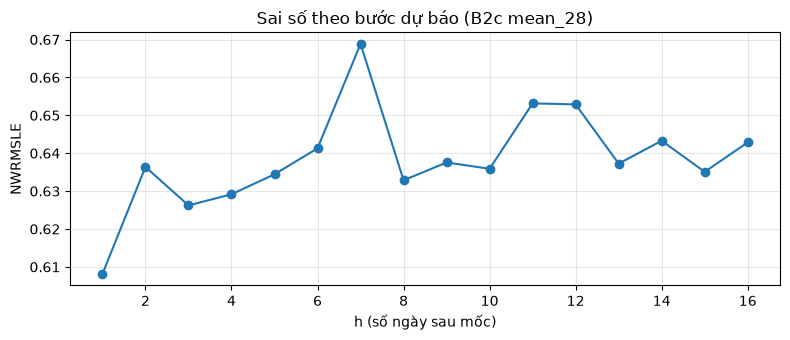

2979

In [23]:
valid_path = files_by_role["valid_last16"][0]
baseline_cols = ["y", "w", "perishable", "pair_status", "h", "has_history", "dow_last", "mean_7", "mean_14", "mean_28",
                 "dow_mean_4", "dow_mean_8", "item_mean_28"]
bv = pq.read_table(valid_path, columns=baseline_cols).to_pandas()

train_ylog = np.concatenate([pq.read_table(p, columns=["y_log"]).column("y_log").to_numpy() for p in train_paths])
B0_CONSTANT = float(np.nanmean(train_ylog))
del train_ylog

preds = {
    "B-zero": np.zeros(len(bv)),
    "B0 (hằng số)": np.full(len(bv), B0_CONSTANT),
    "B1 dow_last": bv["dow_last"].fillna(0).to_numpy(),
    "B2a mean_7": bv["mean_7"].fillna(0).to_numpy(),
    "B2b mean_14": bv["mean_14"].fillna(0).to_numpy(),
    "B2c mean_28": bv["mean_28"].fillna(0).to_numpy(),
    "B3a dow_mean_4": bv["dow_mean_4"].fillna(0).to_numpy(),
    "B3b dow_mean_8": bv["dow_mean_8"].fillna(0).to_numpy(),
    "B4 dow_mean_8 + item_mean_28": bv["dow_mean_8"].fillna(bv["item_mean_28"]).fillna(0).to_numpy(),
}

baseline_rows = []
for name, pred_log in preds.items():
    pred = np.expm1(np.clip(pred_log, 0, None))
    baseline_rows.append({"baseline": name, "NWRMSLE": nwrmsle(bv["y"], pred, bv["perishable"])})
baseline_df = pd.DataFrame(baseline_rows).sort_values("NWRMSLE").reset_index(drop=True)
display(baseline_df.round(5))

BEST_BASELINE = baseline_df.iloc[0]["baseline"]
best_pred = np.expm1(np.clip(preds[BEST_BASELINE], 0, None))
print("Baseline tốt nhất:", BEST_BASELINE)

def breakdown(group_series, label):
    out = []
    for key, idx in bv.groupby(group_series).groups.items():
        idx = np.asarray(idx)
        out.append({label: key, "rows": len(idx), "NWRMSLE": nwrmsle(bv["y"].to_numpy()[idx], best_pred[idx], bv["perishable"].to_numpy()[idx])})
    return pd.DataFrame(out)

by_h = breakdown(bv["h"], "h")
by_perishable = breakdown(bv["perishable"], "perishable")
by_status = breakdown(bv["pair_status"], "pair_status")
by_status["nhóm"] = by_status["pair_status"].map(STATUS_NAMES)
display(by_perishable.round(4)); display(by_status.round(4))

plt.figure(figsize=(8, 3.5))
plt.plot(by_h["h"], by_h["NWRMSLE"], marker="o")
plt.xlabel("h (số ngày sau mốc)"); plt.ylabel("NWRMSLE"); plt.title(f"Sai số theo bước dự báo ({BEST_BASELINE})"); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

baseline_df.to_csv(REPORT_TABLE_DIR / "03_baselines.csv", index=False)
del bv, preds
gc.collect()

**Cách đọc:** đây là mốc mà mô hình ở notebook 04 phải vượt qua trên cùng fold. Nếu `B-zero` không tệ hơn đáng kể các baseline còn lại thì phần lớn dòng có nhãn 0 (nhiều cặp thưa), và chất lượng mô hình sẽ phụ thuộc nhiều vào việc dự báo *có bán hay không*. Sai số theo `pair_status` cho thấy nhóm nào khó nhất.

## 13. Danh mục feature

Mỗi feature được gán nhóm, mô tả, tỷ lệ thiếu (đo trên mốc kiểm định) và tương quan hạng Spearman với `y_log` (đo trên một mẫu). Tương quan chỉ là tín hiệu sơ bộ, không thay cho tầm quan trọng của feature trong mô hình.

Nhóm `exploratory` (giá dầu) có kỳ vọng thấp (01, mục 7.17) và nên được thử riêng ở 04.

In [24]:
DESCRIPTIONS = {
    "h": "Bước dự báo (1..HORIZON)", "dow": "Thứ trong tuần của ngày mục tiêu (0 = Thứ Hai)", "dom": "Ngày trong tháng",
    "month": "Tháng", "woy": "Tuần ISO", "days_to_month_end": "Số ngày tới cuối tháng", "is_payday15": "Ngày 15 hoặc ngày cuối tháng",
    "is_jan1": "Ngày 01/01", "is_dec24_31": "Từ 24 đến 31/12", "days_to_xmas": "Số ngày tới 25/12 gần nhất (tối đa 60)",
    "is_nat_hol": "Lễ quốc gia hiệu lực", "is_reg_hol": "Lễ vùng (khớp state cửa hàng)", "is_loc_hol": "Lễ địa phương (khớp city cửa hàng)",
    "is_event_nat": "Sự kiện quốc gia (Event)", "is_workday": "Ngày làm việc bù (Work Day)",
    "days_to_nat_hol": "Số ngày tới lễ quốc gia kế tiếp (tối đa 30)", "days_since_nat_hol": "Số ngày kể từ lễ quốc gia gần nhất (tối đa 30)",
    "store_type": "Loại cửa hàng (mã)", "store_cluster": "Cụm cửa hàng", "store_state": "Tỉnh (mã)", "store_city": "Thành phố (mã)",
    "item_family": "Nhóm hàng (mã)", "item_class": "Lớp hàng", "perishable": "Hàng mau hỏng",
    "mean_3": "Trung bình log1p(y) 3 ngày cuối", "mean_7": "Trung bình log1p(y) 7 ngày cuối", "mean_14": "Trung bình log1p(y) 14 ngày cuối",
    "mean_28": "Trung bình log1p(y) 28 ngày cuối", "mean_56": "Trung bình log1p(y) 56 ngày cuối", "mean_112": "Trung bình log1p(y) 112 ngày cuối",
    "mean_224": "Trung bình log1p(y) 224 ngày cuối", "std_28": "Độ lệch chuẩn 28 ngày", "max_28": "Giá trị lớn nhất 28 ngày",
    "days_since_last_sale": "Số ngày kể từ lần bán cuối (tối đa LOOKBACK)", "pair_age_days": "Số ngày kể từ lần bán đầu tiên",
    "trend_7_28": "mean_7 trừ mean_28", "trend_28_112": "mean_28 trừ mean_112",
    "promo_days_7": "Số ngày có khuyến mãi (trong 7 ngày cuối, chỉ tính ngày có dòng bán)", "promo_days_28": "Như trên, 28 ngày",
    "promo_share_sale_days_28": "Tỷ lệ ngày bán có khuyến mãi trong 28 ngày cuối",
    "dow_last": "Giá trị lần gần nhất cùng thứ trong tuần", "dow_mean_4": "Trung bình 4 lần cùng thứ gần nhất",
    "dow_mean_8": "Trung bình 8 lần cùng thứ gần nhất", "dow_mean_16": "Trung bình 16 lần cùng thứ gần nhất",
    "dow_act_8": "Tỷ lệ có bán trong 8 lần cùng thứ gần nhất", "dow_ratio_8": "dow_mean_8 trừ mean_56",
    "item_mean_28": "Mức bán trung bình 28 ngày của item trên các cửa hàng", "item_act_28": "Tần suất bán trung bình của item",
    "item_nstores_active_28": "Số cửa hàng đang bán item", "store_mean_28": "Mức bán trung bình 28 ngày của cửa hàng",
    "store_nitems_active_28": "Số mặt hàng đang bán của cửa hàng", "family_store_mean_28": "Mức bán trung bình của nhóm hàng tại cửa hàng",
    "class_mean_28": "Mức bán trung bình của lớp hàng", "item_age_days": "Số ngày kể từ lần bán đầu tiên của item",
    "store_dow_idx": "Hệ số thứ trong tuần của cửa hàng", "store_tx_7": "Số giao dịch TB 7 ngày cuối của cửa hàng",
    "store_tx_28": "Số giao dịch TB 28 ngày cuối của cửa hàng", "store_tx_ratio": "store_tx_7 chia store_tx_28",
    "store_age_days": "Tuổi cửa hàng (ngày)", "promo_t": "Có khuyến mãi vào ngày mục tiêu", "promo_h_sum": "Số ngày khuyến mãi của cặp trong horizon",
    "item_promo_share_t": "Tỷ lệ cặp của item có khuyến mãi ngày mục tiêu", "store_promo_share_t": "Tỷ lệ cặp của cửa hàng có khuyến mãi ngày mục tiêu",
    "promo_known_t": "Ngày mục tiêu thuộc giai đoạn đã ghi nhận khuyến mãi", "oil_T": "Giá dầu tại mốc (điền tiến)", "oil_chg_28": "Biến động giá dầu 28 ngày",
    "has_history": "Cặp có lịch sử tại mốc", "pair_status": "Nhóm cặp (0..3)",
}
META_COLS = ["store_nbr", "item_nbr", "origin", "date", "id", "y", "y_log", "w"]
FUTURE_PROMO = ["promo_t", "promo_h_sum", "item_promo_share_t", "store_promo_share_t", "promo_known_t"]


def group_of(name):
    if name in META_COLS:
        return "meta/nhãn"
    if name in ("oil_T", "oil_chg_28"):
        return "exploratory"
    if name in FUTURE_PROMO:
        return "khuyến mãi tương lai (rủi ro)"
    if name.startswith("promo"):
        return "khuyến mãi lịch sử"
    if name.startswith("dow_") and name != "dow":
        return "cùng thứ trong tuần"
    if name in ("dow", "dom", "month", "woy", "h", "days_to_month_end", "is_payday15", "is_jan1", "is_dec24_31", "days_to_xmas") or name.startswith("is_") or "nat_hol" in name:
        return "lịch / ngày lễ"
    if name in ("store_type", "store_cluster", "store_state", "store_city", "item_family", "item_class", "perishable"):
        return "metadata"
    if name.startswith(("item_", "store_", "family_", "class_")):
        return "phân cấp / cửa hàng"
    if name in ("has_history", "pair_status"):
        return "trạng thái cặp"
    return "lịch sử cặp"


sample_v = read_columns(files_by_role["valid_last16"], [c for c in schema_names], max_rows=300_000)
feature_names = [c for c in schema_names if c not in META_COLS]

corr_rows = []
for name in feature_names:
    col = sample_v[name]
    rho = col.corr(sample_v["y_log"], method="spearman") if col.nunique(dropna=True) > 1 else np.nan
    corr_rows.append({"feature": name, "nhóm": group_of(name), "mô tả": DESCRIPTIONS.get(name, ""),
                      "dtype": str(dataset_all.schema.field(name).type), "null_pct": col.isna().mean() * 100,
                      "rủi ro": ("khuyến mãi chỉ quan sát khi có dòng bán ở train (mục 11.3)" if name in FUTURE_PROMO[:4] else ""),
                      "spearman_với_y_log": rho})
catalog_df = pd.DataFrame(corr_rows)
catalog_df["|rho|"] = catalog_df["spearman_với_y_log"].abs()
catalog_df = catalog_df.sort_values(["nhóm", "|rho|"], ascending=[True, False]).drop(columns="|rho|").reset_index(drop=True)
catalog_df.to_csv(REPORT_TABLE_DIR / "03_feature_catalog.csv", index=False)

print(f"{len(feature_names)} feature | nhóm:")
display(catalog_df.groupby("nhóm").size().rename("số feature").to_frame().T)
display(catalog_df.sort_values("spearman_với_y_log", key=lambda s: s.abs(), ascending=False).head(20)[["feature", "nhóm", "null_pct", "spearman_với_y_log"]].round(3))
del sample_v
gc.collect()

75 feature | nhóm:


nhóm,cùng thứ trong tuần,exploratory,khuyến mãi lịch sử,khuyến mãi tương lai (rủi ro),lịch / ngày lễ,lịch sử cặp,metadata,phân cấp / cửa hàng,trạng thái cặp
số feature,6,2,3,5,17,20,7,13,2


,feature,nhóm,null_pct,spearman_với_y_log
33,mean_28,lịch sử cặp,0.000,0.768
34,mean_14,lịch sử cặp,0.000,0.767
35,mean_56,lịch sử cặp,0.000,0.760
36,mean_7,lịch sử cặp,0.000,0.760
0,dow_mean_8,cùng thứ trong tuần,0.047,0.748
37,mean_112,lịch sử cặp,0.000,0.746
1,dow_mean_4,cùng thứ trong tuần,0.047,0.742
2,dow_mean_16,cùng thứ trong tuần,0.047,0.741
38,mean_3,lịch sử cặp,0.000,0.740
39,act_28,lịch sử cặp,0.000,0.738


31

**Tỷ lệ thiếu cần hiểu đúng:** các feature lịch sử có `null_pct` thấp ở mốc kiểm định (mọi cặp đều có lịch sử), nhưng ở mốc test, `has_history = 0` (cặp mới) làm các feature lịch sử là NaN; LightGBM xử lý NaN tự nhiên, còn các mô hình khác cần quy tắc điền riêng. Các feature `promo_days_*`, `promo_share_sale_days_28` là NaN khi không có dòng bán trong cửa sổ.

## 14. Cấu hình bàn giao cho notebook 04

Gồm: bảng fold, quy tắc chọn mốc huấn luyện, ước tính bộ nhớ, và hàm đọc dữ liệu dùng chung. Mọi thứ được lưu vào `reports/03_config.json` để 04 không phải lặp lại logic.

In [25]:
valid_last = run_plan[run_plan["role"] == "valid_last16"].iloc[0]["origin"]
folds = [{"fold": "V1_last16", "valid_origin": valid_last, "valid_role": "valid_last16"}]
if (plan_df["role"] == "valid_seasonal").any():
    folds.append({"fold": "V2_seasonal", "valid_origin": SEASONAL_VALID_ORIGIN, "valid_role": "valid_seasonal"})
folds_df = pd.DataFrame(folds)

train_manifest = manifest[manifest["role"] == "train"].copy()
rows = []
for f in folds:
    usable = train_manifest[train_manifest["origin"] + pd.Timedelta(days=HORIZON) <= f["valid_origin"]]
    rows.append({"fold": f["fold"], "valid_origin": f["valid_origin"], "train_origins": len(usable), "train_rows": int(usable["rows"].sum()),
                 "first_train_origin": usable["origin"].min(), "last_train_origin": usable["origin"].max()})
fold_summary = pd.DataFrame(rows)
display(fold_summary)

n_features = len(feature_names)
total_train_rows = int(train_manifest["rows"].sum())
est_gb = total_train_rows * n_features * 4 / 1024**3
print(f"Dữ liệu huấn luyện: {total_train_rows:,} dòng x {n_features} feature x 4 byte ≈ {est_gb:.2f} GB (float32, trước khi LightGBM tạo bản nhị phân hóa)")
if psutil is not None:
    avail = psutil.virtual_memory().available / 1024**3
    print(f"RAM khả dụng hiện tại: {avail:.2f} GB ->", "OK" if est_gb < 0.5 * avail else "CÓ THỂ THIẾU RAM: giảm TARGET_TRAIN_ROWS, chọn nhóm feature, hoặc lọc theo cửa sổ thời gian ở notebook 04")


def load_features(roles=("train",), columns=None, origin_min=None, origin_max=None, max_rows=None, seed=SEED):
    # Đọc bảng feature theo vai trò và khoảng ngày mốc. Dùng ở notebook 04.
    paths = []
    for role in roles:
        paths.extend(files_by_role.get(role, []))
    parts = []
    for p in paths:
        o = pd.Timestamp(p.stem.split("_")[-1])            # tên file có dạng <role>_YYYYMMDD
        if (origin_min is not None and o < origin_min) or (origin_max is not None and o > origin_max):
            continue
        parts.append(pq.read_table(p, columns=columns).to_pandas())
    out = pd.concat(parts, ignore_index=True) if parts else pd.DataFrame(columns=columns)
    if max_rows is not None and len(out) > max_rows:
        out = out.sample(max_rows, random_state=seed).reset_index(drop=True)
    return out


demo = load_features(("valid_last16",), columns=["origin", "h", "y_log"], max_rows=1000)
print("Kiểm thử load_features:", demo.shape)

,fold,valid_origin,train_origins,train_rows,first_train_origin,last_train_origin
0,V1_last16,2017-07-30,53,2905662,2015-06-11,2017-07-04
1,V2_seasonal,2016-08-15,26,1301649,2015-06-11,2016-07-18


Dữ liệu huấn luyện: 2,970,590 dòng x 75 feature x 4 byte ≈ 0.83 GB (float32, trước khi LightGBM tạo bản nhị phân hóa)
RAM khả dụng hiện tại: 1.33 GB -> CÓ THỂ THIẾU RAM: giảm TARGET_TRAIN_ROWS, chọn nhóm feature, hoặc lọc theo cửa sổ thời gian ở notebook 04
Kiểm thử load_features: (1000, 3)


In [26]:
config = {
    "created_at": datetime.now().isoformat(timespec="seconds"),
    "seed": SEED, "horizon": HORIZON, "lookback": LOOKBACK, "windows": WINDOWS, "dow_occurrences": DOW_OCCURRENCES,
    "origin_step_days": ORIGIN_STEP_DAYS, "train_origin_start": TRAIN_ORIGIN_START.isoformat(), "test_origin": TEST_ORIGIN.isoformat(),
    "quake_window": [QUAKE_START.isoformat(), QUAKE_END.isoformat()],
    "target_train_rows": TARGET_TRAIN_ROWS, "train_pair_frac": TRAIN_PAIR_FRAC,
    "feature_dir": str(FEATURE_DIR.relative_to(PROJECT_ROOT)),
    "target": "y_log = log1p(clip(unit_sales, 0))", "weight": "w (perishable = 1.25, còn lại 1.0)",
    "train_origin_rule": "mốc huấn luyện T_tr dùng cho fold F nếu T_tr + HORIZON <= T_F",
    "folds": folds_df.to_dict(orient="records"),
    "feature_groups": catalog_df.groupby("nhóm")["feature"].apply(list).to_dict(),
    "meta_columns": META_COLS, "status_names": STATUS_NAMES,
    "baseline_best": {"name": BEST_BASELINE, "nwrmsle": float(baseline_df.iloc[0]["NWRMSLE"])},
}
(REPORT_DIR / "03_config.json").write_text(json.dumps(config, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
print("Đã lưu reports/03_config.json")

Đã lưu reports/03_config.json


## 15. Báo cáo và các hạn chế đã biết

In [27]:
def to_jsonable(value):
    if isinstance(value, dict):
        return {str(k): to_jsonable(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [to_jsonable(v) for v in value]
    if isinstance(value, pd.DataFrame):
        return to_jsonable(value.to_dict(orient="records"))
    if isinstance(value, (pd.Timestamp, datetime)):
        return value.isoformat()
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, np.floating):
        return None if np.isnan(value) else float(value)
    if isinstance(value, np.bool_):
        return bool(value)
    return value


report = {
    "created_at": datetime.now().isoformat(timespec="seconds"),
    "n_features": n_features,
    "manifest": manifest,
    "structure_checks": checks_df,
    "bruteforce_max_abs_diff": float(comparable["abs_diff"].max()),
    "leakage_perturbation_test": "PASS",
    "label_summary": label_df,
    "pair_status_test": status_table,
    "baselines": baseline_df,
    "psi_top": psi_df.head(10),
    "fold_summary": fold_summary,
    "estimated_train_memory_gb": est_gb,
}
(REPORT_DIR / "03_feature_engineering_report.json").write_text(json.dumps(to_jsonable(report), ensure_ascii=False, indent=2), encoding="utf-8")
print("Đã lưu reports/03_feature_engineering_report.json")

Đã lưu reports/03_feature_engineering_report.json


### Hạn chế và lưu ý khi dùng

1. **Cặp mới không có trong dữ liệu huấn luyện.** Universe của mốc huấn luyện chỉ gồm cặp đã có ít nhất một lần bán trước mốc. Cặp mới của test (≈ 21% dòng) vì vậy không được mô hình học trực tiếp; chúng chỉ có feature phân cấp (`item_*`, `store_*`, `family_store_mean_28`, `class_mean_28`). Cần chiến lược riêng ở 04 (quy tắc theo item/cửa hàng, hoặc mô hình riêng), và nên báo cáo sai số theo `pair_status`.
2. **Khuyến mãi tương lai ở huấn luyện chỉ quan sát được ở các ngày có dòng bán** (ngày không có dòng coi là 0), trong khi test cung cấp đủ. Hệ quả là `promo_t = 1` kéo theo `y > 0` trong dữ liệu huấn luyện (mục 11.3); sai số kiểm định của các mô hình dùng nhóm này có thể lạc quan so với test.
3. **Quy ước "ngày vắng = 0"** là giả định (01, mục 7.9): không phân biệt được "không bán" và "không niêm yết". Đã giảm tác động bằng mẫu số hiệu lực theo tuổi cặp và bằng việc loại store-day không có dữ liệu, nhưng cặp ngừng bán vẫn tạo nhiều nhãn 0.
4. **Các mốc huấn luyện chồng lấn thời gian** (cửa sổ mục tiêu 16 ngày, bước 13 ngày) nên các dòng không độc lập; khi tính độ bất định hoặc chọn siêu tham số cần chia theo mốc, không chia theo dòng.
5. **Giai đoạn động đất** (2016-04-16 đến 2016-05-15 và 28 ngày sau) bị loại khỏi các mốc huấn luyện, nhưng ảnh hưởng của nó vẫn có thể còn trong lịch sử 224 ngày của các mốc sau đó.
6. **`transactions` và giá dầu** chỉ dùng ở dạng đã biết tại mốc; không dùng giá trị cùng ngày với ngày mục tiêu.
7. **Lấy mẫu cặp** được thực hiện sau khi tính feature phân cấp trên toàn universe, nên các feature phân cấp không bị lệch bởi việc lấy mẫu.

### Bước tiếp theo — `04_modeling`

1. Đọc `reports/03_config.json`; dùng `load_features()`.
2. Huấn luyện LightGBM trên `y_log` với trọng số `w`; kiểm định trên fold V1 và V2 (quy tắc chống chồng lấn ở mục 5).
3. So sánh với các baseline ở mục 12; báo cáo sai số theo `pair_status`, `perishable`, `h`.
4. Thử nghiệm cửa sổ huấn luyện (toàn bộ, từ 2015-06, từ 2016) bằng cách lọc cột `origin`.
5. Thử nghiệm có và không có nhóm `khuyến mãi tương lai (rủi ro)` (mục 11.3) và nhóm `exploratory`.
6. Xây chiến lược riêng cho cặp mới (`pair_status` 2 và 3).